In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Tropical_Cyclone_MLFF"

folders = [
    "data/raw",
    "data/processed",
    "data/images",
    "models",
    "outputs",
    "src"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project created successfully!")
print(PROJECT_DIR)

Mounted at /content/drive
Project created successfully!
/content/drive/MyDrive/Tropical_Cyclone_MLFF


In [ ]:
!pip -q install xarray netCDF4 h5netcdf scikit-learn matplotlib seaborn pillow tqdm grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 82.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 87.9 MB/s eta 0:00:00


In [ ]:
import torch
import torchvision
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU available: True


In [ ]:
import os

RAW_DIR = "/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/raw"
os.makedirs(RAW_DIR, exist_ok=True)

print(RAW_DIR)

/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/raw


In [ ]:
import os
import requests

RAW_DIR = "/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/raw"
os.makedirs(RAW_DIR, exist_ok=True)

base_url = "https://www.ncei.noaa.gov/data/hurricane-satellite-hursat-b1/archive/v06/2005/"

files = [
    "HURSAT_b1_v06_2005017S09061_ERNEST_c20170721.tar.gz",
    "HURSAT_b1_v06_2005022S14112_TIM_c20170721.tar.gz",
    "HURSAT_b1_v06_2005035S14136_HARVEY_c20170721.tar.gz"
]

for filename in files:
    url = base_url + filename
    output = os.path.join(RAW_DIR, filename)

    print("Downloading:", filename)

    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(output, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print("Saved:", output)

print("\nAll downloads completed!")

Downloading: HURSAT_b1_v06_2005017S09061_ERNEST_c20170721.tar.gz
Saved: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/raw/HURSAT_b1_v06_2005017S09061_ERNEST_c20170721.tar.gz
Downloading: HURSAT_b1_v06_2005022S14112_TIM_c20170721.tar.gz
Saved: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/raw/HURSAT_b1_v06_2005022S14112_TIM_c20170721.tar.gz
Downloading: HURSAT_b1_v06_2005035S14136_HARVEY_c20170721.tar.gz
Saved: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/raw/HURSAT_b1_v06_2005035S14136_HARVEY_c20170721.tar.gz

All downloads completed!


In [ ]:
import glob
import os

files = glob.glob(RAW_DIR + "/*")

print("Files downloaded:", len(files))

for f in files:
    print(os.path.basename(f))

Files downloaded: 3
HURSAT_b1_v06_2005017S09061_ERNEST_c20170721.tar.gz
HURSAT_b1_v06_2005022S14112_TIM_c20170721.tar.gz
HURSAT_b1_v06_2005035S14136_HARVEY_c20170721.tar.gz


In [ ]:
import tarfile
import glob
import os

EXTRACT_DIR = os.path.join(PROJECT_DIR, "data", "processed", "extracted")
os.makedirs(EXTRACT_DIR, exist_ok=True)

archives = glob.glob(os.path.join(RAW_DIR, "*.tar.gz"))

for archive in archives:
    print("Extracting:", os.path.basename(archive))

    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(EXTRACT_DIR)

print("\nExtraction completed!")

# Find NetCDF files
nc_files = glob.glob(os.path.join(EXTRACT_DIR, "**", "*.nc"), recursive=True)

print("NetCDF files found:", len(nc_files))

for f in nc_files[:20]:
    print(f)

Extracting: HURSAT_b1_v06_2005017S09061_ERNEST_c20170721.tar.gz


/tmp/ipykernel_3642/2490598386.py:14: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(EXTRACT_DIR)


Extracting: HURSAT_b1_v06_2005022S14112_TIM_c20170721.tar.gz
Extracting: HURSAT_b1_v06_2005035S14136_HARVEY_c20170721.tar.gz

Extraction completed!
NetCDF files found: 322
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1200.11.MET-5.015.hursat-b1.v06.nc
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1200.70.MET-7.015.hursat-b1.v06.nc
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1200.70.MSG-1.015.hursat-b1.v06.nc
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1500.11.MET-5.017.hursat-b1.v06.nc
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1500.69.MET-7.017.hursat-b1.v06.nc
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1500.69.MSG-1.017.hursat-b1.v06.nc
/conte

In [ ]:
import xarray as xr
import os

# Open the first NetCDF file
sample_file = nc_files[0]

print("Opening:")
print(sample_file)

ds = xr.open_dataset(sample_file)

print("\n========== DATASET ==========")
print(ds)

print("\n========== VARIABLES ==========")
for name in ds.data_vars:
    var = ds[name]
    print(f"{name:25s} | dims={var.dims} | shape={var.shape} | dtype={var.dtype}")

print("\n========== COORDINATES ==========")
for name in ds.coords:
    print(name, ds[name].shape)

print("\n========== ATTRIBUTES ==========")
for key, value in ds.attrs.items():
    print(key, ":", value)

Opening:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1200.11.MET-5.015.hursat-b1.v06.nc

========== DATASET ==========
<xarray.Dataset> Size: 1MB
Dimensions:             (htime: 1, lat: 301, lon: 301, rad10: 70)
Coordinates:
  * htime               (htime) datetime64[ns] 8B 2005-01-16T11:59:59.999959808
  * lat                 (lat) float32 1kB -19.2 -19.13 -19.06 ... 1.66 1.73 1.8
  * lon                 (lon) float32 1kB 50.3 50.37 50.44 ... 71.16 71.23 71.3
Dimensions without coordinates: rad10
Data variables: (12/54)
    fname               (htime) |S128 128B ...
    sid                 (htime) |S13 13B ...
    NomDate             (htime) int32 4B ...
    NomTime             (htime) int32 4B ...
    sss                 (htime) int32 4B ...
    nchan               (htime) int32 4B ...
    ...                  ...
    ang_vcen            (htime) float32 4B ...
    tavg_vcen           (htime, rad10) float32 280B ...
    tmin_vc

In [ ]:
print("========== CHANNEL INFORMATION ==========")

for var_name in ["IRWIN", "IRWVP", "VSCHN", "WindSpd", "CentPrs"]:
    var = ds[var_name]

    print(f"\n{var_name}")
    print("  Shape:", var.shape)
    print("  Units:", var.attrs.get("units", "Not specified"))
    print("  Long name:", var.attrs.get("long_name", "Not specified"))
    print("  Min:", float(var.min(skipna=True)))
    print("  Max:", float(var.max(skipna=True)))
    print("  Mean:", float(var.mean(skipna=True)))

print("\n========== CYCLONE INFORMATION ==========")
print("Storm:", ds.attrs.get("TC_name"))
print("Wind Speed:", float(ds["WindSpd"].values[0]))
print("Central Pressure:", float(ds["CentPrs"].values[0]))
print("Satellite:", ds.attrs.get("Satellite_Name"))
print("Observation time:", ds["htime"].values[0])

========== CHANNEL INFORMATION ==========

IRWIN
  Shape: (1, 301, 301)
  Units: Kelvin
  Long name: Brightness Temperature in (10.6-11.8 um)
  Min: 198.32000732421875
  Max: 298.20001220703125
  Mean: 270.6304016113281

IRWVP
  Shape: (1, 301, 301)
  Units: Kelvin
  Long name: Brightness Temperature in (5.73-6.84 um)
  Min: 204.5
  Max: 252.88999938964844
  Mean: 239.62991333007812

VSCHN
  Shape: (1, 301, 301)
  Units: Not specified
  Long name: Visible Reflectance in (0.46-0.87 um)
  Min: 0.010000000707805157
  Max: 0.7720000147819519
  Mean: 0.15719246864318848

WindSpd
  Shape: (1,)
  Units: knots
  Long name: Wind Speed
  Min: 15.466667175292969
  Max: 15.466667175292969
  Mean: 15.466667175292969

CentPrs
  Shape: (1,)
  Units: mb
  Long name: Central Pressure
  Min: 1006.5
  Max: 1006.5
  Mean: 1006.5

========== CYCLONE INFORMATION ==========
Storm: ERNEST
Wind Speed: 15.466667175292969
Central Pressure: 1006.5
Satellite: Meteosat-5
Observation time: 2005-01-16T11:59:59.999959

In [ ]:
import pandas as pd
import glob
import xarray as xr
import os

records = []

for file in nc_files:
    try:
        data = xr.open_dataset(file)

        record = {
            "file": file,
            "storm": data.attrs.get("TC_name", "UNKNOWN"),
            "satellite": data.attrs.get("Satellite_Name", "UNKNOWN"),
            "time": str(data["htime"].values[0]),
            "wind": float(data["WindSpd"].values[0]),
            "pressure": float(data["CentPrs"].values[0])
        }

        records.append(record)
        data.close()

    except Exception as e:
        print("Error:", file, e)

metadata_df = pd.DataFrame(records)

print("Total observations:", len(metadata_df))
print("\nStorm distribution:")
print(metadata_df["storm"].value_counts())

print("\nWind-speed statistics:")
print(metadata_df["wind"].describe())

print("\nFirst 20 observations:")
display(metadata_df.head(20))

Total observations: 322

Storm distribution:
storm
ERNEST    213
TIM        74
HARVEY     35
Name: count, dtype: int64

Wind-speed statistics:
count    322.000000
mean      41.212216
std       21.641437
min       15.466667
25%       24.266668
50%       32.616667
75%       59.749999
max       88.666664
Name: wind, dtype: float64

First 20 observations:


,file,storm,satellite,time,wind,pressure
0,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-5,2005-01-16T11:59:59.999959808,15.466667,1006.5
1,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-7,2005-01-16T11:59:59.999959808,15.466667,1006.5
2,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-8,2005-01-16T11:59:59.999959808,15.466667,1006.5
3,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-5,2005-01-16T14:59:59.999959808,16.933334,1006.0
4,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-7,2005-01-16T14:59:59.999959808,16.933334,1006.0
5,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-8,2005-01-16T14:59:59.999959808,16.933334,1006.0
6,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-5,2005-01-16T17:59:59.999959808,18.400000,1005.5
7,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-7,2005-01-16T17:59:59.999959808,18.400000,1005.5
8,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-8,2005-01-16T17:59:59.999959808,18.400000,1005.5
9,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,Meteosat-5,2005-01-16T20:59:59.999959808,19.866667,1005.0


In [ ]:
import numpy as np
import pandas as pd

def classify_cyclone(wind):
    """
    Wind speed is interpreted in knots for HURSAT WindSpd.

    Classes:
    0 = Tropical Depression
    1 = Tropical Storm
    2 = Hurricane/Typhoon strength
    """

    if wind < 34:
        return 0
    elif wind < 64:
        return 1
    else:
        return 2


metadata_df["label"] = metadata_df["wind"].apply(classify_cyclone)

label_names = {
    0: "Tropical Depression",
    1: "Tropical Storm",
    2: "Hurricane/Typhoon"
}

metadata_df["class_name"] = metadata_df["label"].map(label_names)

print("========== CLASS DISTRIBUTION ==========")
print(metadata_df["class_name"].value_counts())

print("\n========== NUMERIC DISTRIBUTION ==========")
print(metadata_df["label"].value_counts().sort_index())

display(
    metadata_df[
        ["storm", "time", "wind", "pressure", "class_name"]
    ].head(20)
)

========== CLASS DISTRIBUTION ==========
class_name
Tropical Depression    175
Tropical Storm          87
Hurricane/Typhoon       60
Name: count, dtype: int64

========== NUMERIC DISTRIBUTION ==========
label
0    175
1     87
2     60
Name: count, dtype: int64


,storm,time,wind,pressure,class_name
0,ERNEST,2005-01-16T11:59:59.999959808,15.466667,1006.5,Tropical Depression
1,ERNEST,2005-01-16T11:59:59.999959808,15.466667,1006.5,Tropical Depression
2,ERNEST,2005-01-16T11:59:59.999959808,15.466667,1006.5,Tropical Depression
3,ERNEST,2005-01-16T14:59:59.999959808,16.933334,1006.0,Tropical Depression
4,ERNEST,2005-01-16T14:59:59.999959808,16.933334,1006.0,Tropical Depression
5,ERNEST,2005-01-16T14:59:59.999959808,16.933334,1006.0,Tropical Depression
6,ERNEST,2005-01-16T17:59:59.999959808,18.400000,1005.5,Tropical Depression
7,ERNEST,2005-01-16T17:59:59.999959808,18.400000,1005.5,Tropical Depression
8,ERNEST,2005-01-16T17:59:59.999959808,18.400000,1005.5,Tropical Depression
9,ERNEST,2005-01-16T20:59:59.999959808,19.866667,1005.0,Tropical Depression


In [ ]:
METADATA_FILE = os.path.join(
    PROJECT_DIR,
    "data",
    "processed",
    "cyclone_metadata.csv"
)

metadata_df.to_csv(METADATA_FILE, index=False)

print("Metadata saved successfully:")
print(METADATA_FILE)

Metadata saved successfully:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/cyclone_metadata.csv


In [ ]:
import numpy as np
import os
from tqdm import tqdm

IMAGE_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed",
    "arrays"
)

os.makedirs(IMAGE_DIR, exist_ok=True)

processed_records = []

for idx, row in tqdm(metadata_df.iterrows(), total=len(metadata_df)):

    try:
        ds_temp = xr.open_dataset(row["file"])

        # Extract the three satellite channels
        irwin = ds_temp["IRWIN"].values[0].astype(np.float32)
        irwvp = ds_temp["IRWVP"].values[0].astype(np.float32)
        vsch = ds_temp["VSCHN"].values[0].astype(np.float32)

        # Replace missing values
        missing_value = -1.0

        irwin[irwin <= missing_value] = np.nan
        irwvp[irwvp <= missing_value] = np.nan
        vsch[vsch <= missing_value] = np.nan

        # Replace remaining NaN/Inf values
        irwin = np.nan_to_num(irwin, nan=0.0, posinf=0.0, neginf=0.0)
        irwvp = np.nan_to_num(irwvp, nan=0.0, posinf=0.0, neginf=0.0)
        vsch = np.nan_to_num(vsch, nan=0.0, posinf=0.0, neginf=0.0)

        # Stack into 3-channel tensor
        image = np.stack(
            [irwin, irwvp, vsch],
            axis=0
        )

        # Save as NumPy array
        output_name = f"sample_{idx:05d}.npy"
        output_path = os.path.join(IMAGE_DIR, output_name)

        np.save(output_path, image)

        processed_records.append({
            "array_path": output_path,
            "storm": row["storm"],
            "time": row["time"],
            "wind": row["wind"],
            "pressure": row["pressure"],
            "label": row["label"],
            "class_name": row["class_name"]
        })

        ds_temp.close()

    except Exception as e:
        print("Error processing:", row["file"])
        print(e)

processed_df = pd.DataFrame(processed_records)

print("\nProcessing completed!")
print("Samples created:", len(processed_df))
print("Tensor shape:", np.load(processed_df.iloc[0]["array_path"]).shape)

 70%|███████   | 226/322 [00:14<00:04, 20.31it/s]

Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005022S14112.TIM.2005.01.22.1200.52.GOE-9.017.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005022S14112.TIM.2005.01.22.1500.52.GOE-9.017.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005022S14112.TIM.2005.01.22.1800.53.GOE-9.017.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"


 75%|███████▌  | 242/322 [00:15<00:04, 19.23it/s]

Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005022S14112.TIM.2005.01.23.1200.54.GOE-9.031.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005022S14112.TIM.2005.01.23.1500.55.GOE-9.033.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005022S14112.TIM.2005.01.23.1800.55.GOE-9.036.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"


 80%|████████  | 259/322 [00:16<00:03, 20.01it/s]

...

Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.05.1200.24.GOE-9.025.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.05.1500.24.GOE-9.027.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.05.1800.24.GOE-9.028.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"


 98%|█████████▊| 314/322 [00:20<00:00, 14.86it/s]

Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.06.1200.25.GOE-9.034.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.06.1500.25.GOE-9.036.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.06.1800.25.GOE-9.038.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"


100%|██████████| 322/322 [00:20<00:00, 15.60it/s]

Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.07.1200.28.GOE-9.048.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.07.1500.29.GOE-9.041.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"
Error processing: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/extracted/2005035S14136.HARVEY.2005.02.07.1800.29.GOE-9.033.hursat-b1.v06.nc
"No variable named 'VSCHN'. Variables on the dataset include ['fname', 'sid', 'NomDate', 'NomTime', 'sss', ..., 'tstd_vcen', 'tnum_vcen', 'lat', 'lon', 'htime']"

Processing completed!
Samples created: 294
Tenso

In [ ]:
PROCESSED_CSV = os.path.join(
    PROJECT_DIR,
    "data",
    "processed",
    "processed_dataset.csv"
)

processed_df.to_csv(PROCESSED_CSV, index=False)

print("Processed dataset saved:")
print(PROCESSED_CSV)

print("\nClass distribution:")
print(processed_df["class_name"].value_counts())

Processed dataset saved:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/processed_dataset.csv

Class distribution:
class_name
Tropical Depression    152
Tropical Storm          82
Hurricane/Typhoon       60
Name: count, dtype: int64


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import os

class CycloneDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # Load 3-channel satellite tensor
        image = np.load(row["array_path"]).astype(np.float32)

        # Per-channel normalization
        for c in range(3):
            mean = image[c].mean()
            std = image[c].std()

            if std > 1e-6:
                image[c] = (image[c] - mean) / std
            else:
                image[c] = image[c] - mean

        image = torch.tensor(image, dtype=torch.float32)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label

In [ ]:
from sklearn.model_selection import train_test_split

df = pd.read_csv(PROCESSED_CSV)

# Remove classes that have too few samples for stratified splitting
class_counts = df["label"].value_counts()

valid_classes = class_counts[class_counts >= 3].index

df = df[df["label"].isin(valid_classes)].reset_index(drop=True)

print("Samples after filtering:", len(df))
print("\nClass distribution:")
print(df["class_name"].value_counts())

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("\n========== DATASET SPLIT ==========")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nTraining classes:")
print(train_df["class_name"].value_counts())

print("\nValidation classes:")
print(val_df["class_name"].value_counts())

print("\nTesting classes:")
print(test_df["class_name"].value_counts())

Samples after filtering: 294

Class distribution:
class_name
Tropical Depression    152
Tropical Storm          82
Hurricane/Typhoon       60
Name: count, dtype: int64

========== DATASET SPLIT ==========
Training: 205
Validation: 44
Testing: 45

Training classes:
class_name
Tropical Depression    106
Tropical Storm          57
Hurricane/Typhoon       42
Name: count, dtype: int64

Validation classes:
class_name
Tropical Depression    23
Tropical Storm         12
Hurricane/Typhoon       9
Name: count, dtype: int64

Testing classes:
class_name
Tropical Depression    23
Tropical Storm         13
Hurricane/Typhoon       9
Name: count, dtype: int64


In [ ]:
BATCH_SIZE = 16

train_dataset = CycloneDataset(train_df)
val_dataset = CycloneDataset(val_df)
test_dataset = CycloneDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

# Check one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Labels:", labels)

DataLoaders created successfully!

Batch image shape: torch.Size([16, 3, 301, 301])
Batch label shape: torch.Size([16])
Labels: tensor([0, 1, 1, 0, 0, 0, 0, 1, 0, 2, 0, 2, 0, 0, 0, 0])


In [ ]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_CLASSES = len(sorted(df["label"].unique()))

print("Device:", DEVICE)
print("Number of classes:", NUM_CLASSES)

print("\nClass mapping:")
for label, name in label_names.items():
    if label in df["label"].unique():
        print(label, "->", name)

Device: cuda
Number of classes: 3

Class mapping:
0 -> Tropical Depression
1 -> Tropical Storm
2 -> Hurricane/Typhoon


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# -----------------------------------------
# Basic Convolution Block
# -----------------------------------------
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


# -----------------------------------------
# Channel Attention
# -----------------------------------------
class ChannelAttention(nn.Module):

    def __init__(self, channels, reduction=16):
        super().__init__()

        hidden = max(channels // reduction, 1)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        attention = self.fc(self.avg_pool(x))
        return x * attention


# -----------------------------------------
# Spatial Attention
# -----------------------------------------
class SpatialAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=7,
            padding=3,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_map = torch.mean(x, dim=1, keepdim=True)
        max_map, _ = torch.max(x, dim=1, keepdim=True)

        combined = torch.cat(
            [avg_map, max_map],
            dim=1
        )

        attention = self.sigmoid(
            self.conv(combined)
        )

        return x * attention


# -----------------------------------------
# Multi-Level Feature Fusion
# -----------------------------------------
class MLFFBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = ConvBlock(
            in_channels,
            out_channels
        )

        self.conv2 = ConvBlock(
            out_channels,
            out_channels
        )

        self.conv3 = ConvBlock(
            out_channels,
            out_channels
        )

    def forward(self, x):

        # Low-level features
        low = self.conv1(x)

        # Mid-level features
        mid = self.conv2(low)

        # High-level features
        high = self.conv3(mid)

        # Multi-level fusion
        fused = low + mid + high

        return fused


# -----------------------------------------
# MLFF-CycloneNet
# -----------------------------------------
class MLFFCycloneNet(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        # Initial satellite feature extraction
        self.stem = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2)
        )


        # Level 1
        self.level1 = MLFFBlock(
            32,
            64
        )

        self.pool1 = nn.MaxPool2d(2)


        # Level 2
        self.level2 = MLFFBlock(
            64,
            128
        )

        self.pool2 = nn.MaxPool2d(2)


        # Level 3
        self.level3 = MLFFBlock(
            128,
            256
        )


        # Feature fusion projections
        self.proj1 = nn.Conv2d(
            64,
            256,
            kernel_size=1
        )

        self.proj2 = nn.Conv2d(
            128,
            256,
            kernel_size=1
        )


        # Attention
        self.channel_attention = ChannelAttention(
            256
        )

        self.spatial_attention = SpatialAttention()


        # Global feature extraction
        self.global_pool = nn.AdaptiveAvgPool2d(1)


        # Classifier
        self.classifier = nn.Sequential(

            nn.Linear(256, 128),

            nn.ReLU(inplace=True),

            nn.Dropout(0.4),

            nn.Linear(
                128,
                num_classes
            )
        )


    def forward(self, x):

        # Stem
        x = self.stem(x)


        # -------------------------
        # Level 1
        # -------------------------
        level1 = self.level1(x)


        # -------------------------
        # Level 2
        # -------------------------
        x2 = self.pool1(level1)

        level2 = self.level2(x2)


        # -------------------------
        # Level 3
        # -------------------------
        x3 = self.pool2(level2)

        level3 = self.level3(x3)


        # -------------------------
        # Multi-Level Fusion
        # -------------------------

        # Convert level 1 to 256 channels
        f1 = self.proj1(level1)

        # Convert level 2 to 256 channels
        f2 = self.proj2(level2)

        # Resize features to level-3 resolution
        f1 = F.interpolate(
            f1,
            size=level3.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        f2 = F.interpolate(
            f2,
            size=level3.shape[-2:],
            mode="bilinear",
            align_corners=False
        )


        # Fuse low + middle + high features
        fused = f1 + f2 + level3


        # Attention
        fused = self.channel_attention(fused)

        fused = self.spatial_attention(fused)


        # Global pooling
        features = self.global_pool(fused)

        features = torch.flatten(
            features,
            1
        )


        # Classification
        output = self.classifier(features)

        return output

In [ ]:
model = MLFFCycloneNet(
    num_classes=NUM_CLASSES
)

model = model.to(DEVICE)

print(model)

MLFFCycloneNet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (level1): MLFFBlock(
    (conv1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
    (conv2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (

In [ ]:
images, labels = next(iter(train_loader))

images = images.to(DEVICE)

with torch.no_grad():
    outputs = model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)

print("\nModel test successful!")

Input shape : torch.Size([16, 3, 301, 301])
Output shape: torch.Size([16, 3])

Model test successful!


In [ ]:
import torch
import torch.nn as nn

# Cross-entropy loss for multi-class classification
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Reduce learning rate when validation loss stops improving
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss function :", criterion)
print("Optimizer     :", optimizer.__class__.__name__)
print("Learning rate :", optimizer.param_groups[0]["lr"])

Loss function : CrossEntropyLoss()
Optimizer     : Adam
Learning rate : 0.001


In [ ]:
from sklearn.metrics import accuracy_score
from tqdm import tqdm

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        progress.set_postfix(
            loss=loss.item()
        )

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return epoch_loss, epoch_accuracy

In [ ]:
import os
import time

EPOCHS = 10

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "MLFF_CycloneNet_best.pth"
)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")

print("Starting training...")
print("Device:", DEVICE)
print("Epochs:", EPOCHS)

for epoch in range(EPOCHS):

    start_time = time.time()

    print(
        f"\n========== Epoch {epoch + 1}/{EPOCHS} =========="
    )

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    # Update learning rate
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    elapsed = time.time() - start_time

    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.4f}")
    print(f"Val Loss       : {val_loss:.4f}")
    print(f"Val Accuracy   : {val_acc:.4f}")
    print(f"Learning Rate  : {current_lr:.6f}")
    print(f"Time           : {elapsed:.1f} seconds")

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "num_classes": NUM_CLASSES,
                "class_names": label_names,
                "best_val_loss": best_val_loss
            },
            BEST_MODEL_PATH
        )

        print("✓ Best model saved!")

print("\nTraining completed!")
print("Best model:", BEST_MODEL_PATH)

Starting training...
Device: cuda
Epochs: 10

========== Epoch 1/10 ==========


Train Loss     : 1.0645
Train Accuracy : 0.4780
Val Loss       : 1.5007
Val Accuracy   : 0.5227
Learning Rate  : 0.001000
Time           : 6.3 seconds
✓ Best model saved!

========== Epoch 2/10 ==========


Train Loss     : 1.0135
Train Accuracy : 0.5171
Val Loss       : 2.8541
Val Accuracy   : 0.5227
Learning Rate  : 0.001000
Time           : 5.3 seconds

========== Epoch 3/10 ==========


Train Loss     : 1.0156
Train Accuracy : 0.5220
Val Loss       : 7.0906
Val Accuracy   : 0.5227
Learning Rate  : 0.001000
Time           : 5.2 seconds

========== Epoch 4/10 ==========


Train Loss     : 0.9368
Train Accuracy : 0.5268
Val Loss       : 1.7369
Val Accuracy   : 0.5227
Learning Rate  : 0.000500
Time           : 5.3 seconds

========== Epoch 5/10 ==========


...

Train Loss     : 0.8457
Train Accuracy : 0.5707
Val Loss       : 0.7925
Val Accuracy   : 0.5682
Learning Rate  : 0.000500
Time           : 5.2 seconds
✓ Best model saved!

========== Epoch 7/10 ==========


Train Loss     : 0.8043
Train Accuracy : 0.6000
Val Loss       : 0.8908
Val Accuracy   : 0.6591
Learning Rate  : 0.000500
Time           : 5.4 seconds

========== Epoch 8/10 ==========


Train Loss     : 0.7724
Train Accuracy : 0.6293
Val Loss       : 0.6415
Val Accuracy   : 0.6591
Learning Rate  : 0.000500
Time           : 5.6 seconds
✓ Best model saved!

========== Epoch 9/10 ==========


Train Loss     : 0.7278
Train Accuracy : 0.6439
Val Loss       : 1.2477
Val Accuracy   : 0.3409
Learning Rate  : 0.000500
Time           : 5.4 seconds

========== Epoch 10/10 ==========


Train Loss     : 0.6649
Train Accuracy : 0.6927
Val Loss       : 0.9187
Val Accuracy   : 0.5909
Learning Rate  : 0.000500
Time           : 5.6 seconds

Training completed!
Best model: /content/drive/MyDrive/Tropical_Cyclone_MLFF/models/MLFF_CycloneNet_best.pth


In [ ]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best saved model
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

# Convert to arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

# Metrics
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

print("========== TEST RESULTS ==========")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")

class_ids = sorted(
    np.unique(
        np.concatenate(
            [all_labels, all_predictions]
        )
    )
)

class_names = [
    label_names[i]
    for i in class_ids
]

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    )
)

========== TEST RESULTS ==========
Accuracy  : 0.6444
Precision : 0.6183
Recall    : 0.6444
F1 Score  : 0.5913

========== CLASSIFICATION REPORT ==========
                     precision    recall  f1-score   support

Tropical Depression       0.68      1.00      0.81        23
     Tropical Storm       0.67      0.31      0.42        13
  Hurricane/Typhoon       0.40      0.22      0.29         9

           accuracy                           0.64        45
          macro avg       0.58      0.51      0.50        45
       weighted avg       0.62      0.64      0.59        45



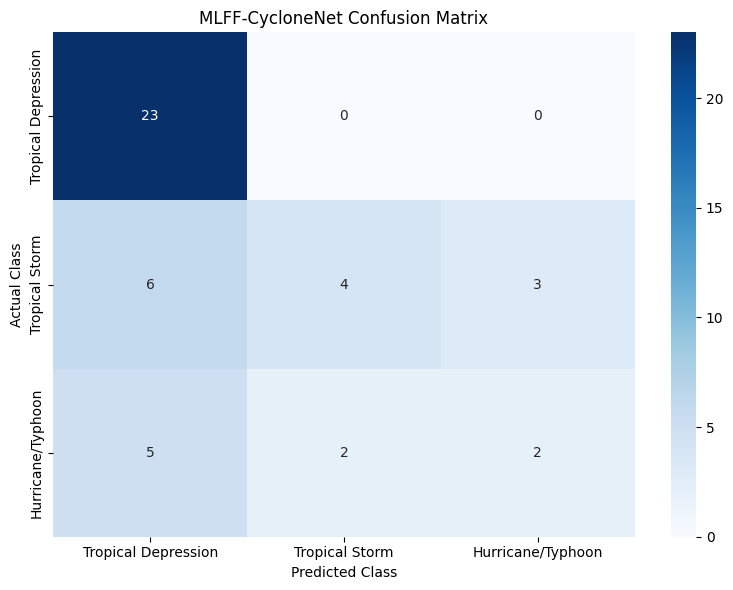

Saved: /content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=class_ids
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MLFF-CycloneNet Confusion Matrix")

plt.tight_layout()

CM_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "confusion_matrix.png"
)

plt.savefig(
    CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", CM_PATH)

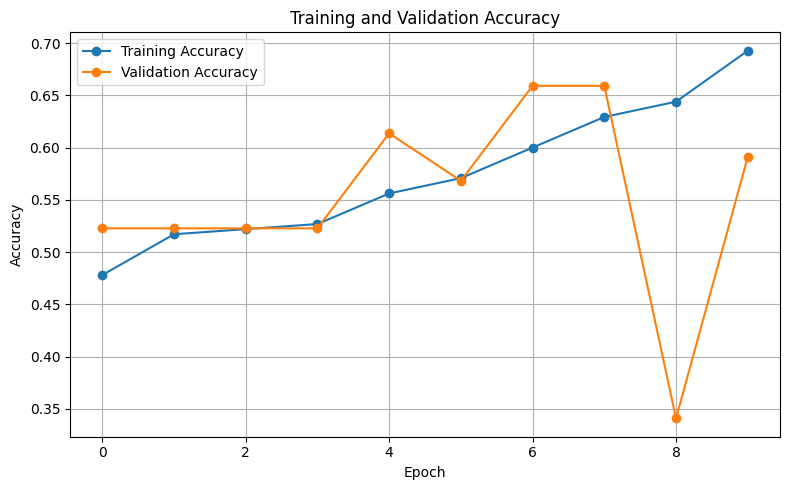

Saved: /content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/accuracy_curve.png


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

ACC_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "accuracy_curve.png"
)

plt.savefig(
    ACC_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", ACC_PATH)

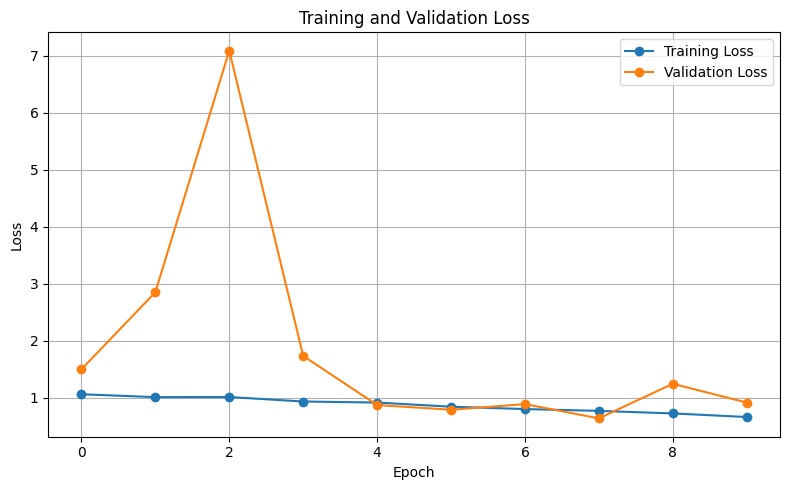

Saved: /content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/loss_curve.png


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

LOSS_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "loss_curve.png"
)

plt.savefig(
    LOSS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", LOSS_PATH)

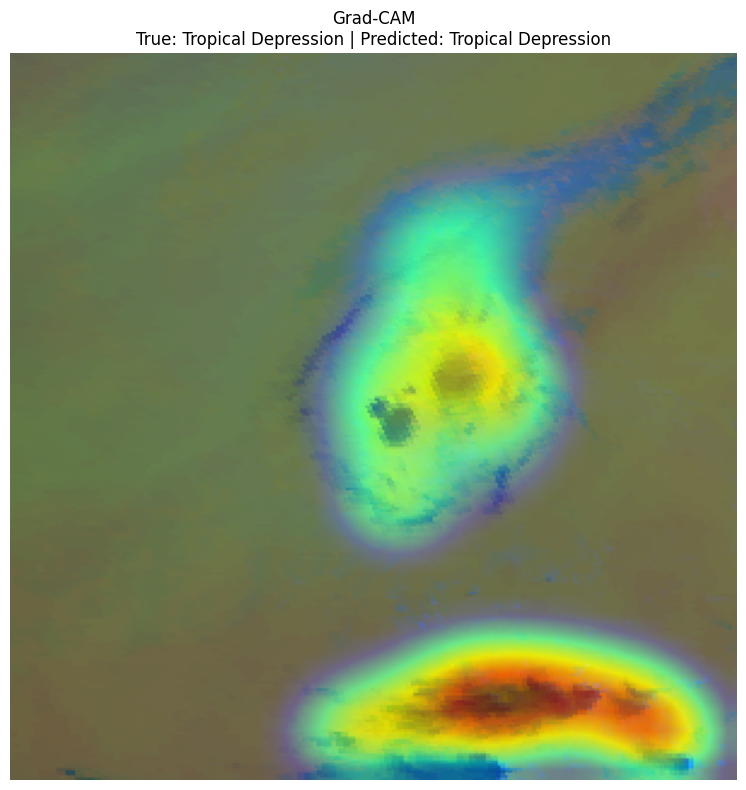

Grad-CAM saved:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/gradcam_example.png


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import numpy as np
import torch
import os

# Target the final high-level feature layer
target_layers = [model.level3.conv3.block[-2]]

# Get one test sample
sample_image, sample_label = test_dataset[0]

input_tensor = sample_image.unsqueeze(0).to(DEVICE)

# Create Grad-CAM
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

# Predict class
model.eval()

with torch.no_grad():
    output = model(input_tensor)

predicted_class = int(
    torch.argmax(output, dim=1).item()
)

true_class = int(sample_label.item())

# Generate CAM
targets = [
    ClassifierOutputTarget(predicted_class)
]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)[0]

# Convert 3-channel satellite input into display image
image_np = sample_image.numpy()

# Normalize each channel for visualization
display_image = np.zeros_like(image_np)

for c in range(3):
    channel = image_np[c]

    min_val = channel.min()
    max_val = channel.max()

    if max_val > min_val:
        display_image[c] = (
            channel - min_val
        ) / (max_val - min_val)

display_image = np.transpose(
    display_image,
    (1, 2, 0)
)

# Overlay Grad-CAM
visualization = show_cam_on_image(
    display_image,
    grayscale_cam,
    use_rgb=True
)

# Display
plt.figure(figsize=(8, 8))

plt.imshow(visualization)

plt.title(
    f"Grad-CAM\n"
    f"True: {label_names[true_class]} | "
    f"Predicted: {label_names[predicted_class]}"
)

plt.axis("off")
plt.tight_layout()

GRADCAM_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "gradcam_example.png"
)

plt.savefig(
    GRADCAM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grad-CAM saved:")
print(GRADCAM_PATH)

In [ ]:
import json

metrics = {
    "model": "MLFF-CycloneNet",
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "num_classes": int(NUM_CLASSES),
    "classes": label_names
}

METRICS_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "evaluation_metrics.json"
)

with open(METRICS_PATH, "w") as f:
    json.dump(
        metrics,
        f,
        indent=4
    )

print("Evaluation metrics saved:")
print(METRICS_PATH)

print("\nFinal metrics:")
for key, value in metrics.items():
    print(key, ":", value)

Evaluation metrics saved:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/evaluation_metrics.json

Final metrics:
model : MLFF-CycloneNet
accuracy : 0.6444444444444445
precision : 0.6183442265795207
recall : 0.6444444444444445
f1_score : 0.591255917571707
num_classes : 3
classes : {0: 'Tropical Depression', 1: 'Tropical Storm', 2: 'Hurricane/Typhoon'}


In [ ]:
HISTORY_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "training_history.json"
)

with open(HISTORY_PATH, "w") as f:
    json.dump(
        history,
        f,
        indent=4
    )

print("Training history saved:")
print(HISTORY_PATH)

Training history saved:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/training_history.json


In [ ]:
import numpy as np
import torch
import os

def predict_cyclone(array_path):

    # Load satellite data
    image = np.load(array_path).astype(np.float32)

    # Normalize each channel
    for c in range(3):

        mean = image[c].mean()
        std = image[c].std()

        if std > 1e-6:
            image[c] = (image[c] - mean) / std
        else:
            image[c] = image[c] - mean

    # Convert to PyTorch tensor
    tensor = torch.tensor(
        image,
        dtype=torch.float32
    ).unsqueeze(0).to(DEVICE)

    # Prediction
    model.eval()

    with torch.no_grad():

        output = model(tensor)

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

        confidence = probabilities[
            0,
            predicted_class
        ].item()

    return predicted_class, confidence, probabilities[0].cpu().numpy()


# Test using one sample
sample_path = test_df.iloc[0]["array_path"]

predicted_class, confidence, probabilities = predict_cyclone(
    sample_path
)

print("========== CYCLONE PREDICTION ==========")
print("Input:", sample_path)
print("Predicted class:", label_names[predicted_class])
print("Confidence:", f"{confidence * 100:.2f}%")

print("\nClass probabilities:")

for class_id, probability in enumerate(probabilities):

    print(
        f"{label_names[class_id]:25s}: "
        f"{probability * 100:.2f}%"
    )

========== CYCLONE PREDICTION ==========
Input: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/arrays/sample_00262.npy
Predicted class: Tropical Depression
Confidence: 97.12%

Class probabilities:
Tropical Depression      : 97.12%
Tropical Storm           : 2.34%
Hurricane/Typhoon        : 0.54%


In [ ]:
def predict_from_file(array_path):

    predicted_class, confidence, probabilities = predict_cyclone(
        array_path
    )

    result = {
        "input_file": array_path,
        "predicted_class": label_names[predicted_class],
        "confidence": float(confidence)
    }

    for class_id, probability in enumerate(probabilities):

        result[
            f"probability_{label_names[class_id]}"
        ] = float(probability)

    return result


# Example
result = predict_from_file(sample_path)

for key, value in result.items():
    print(f"{key}: {value}")

input_file: /content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/arrays/sample_00262.npy
predicted_class: Tropical Depression
confidence: 0.9712385535240173
probability_Tropical Depression: 0.9712385535240173
probability_Tropical Storm: 0.023369818925857544
probability_Hurricane/Typhoon: 0.005391554441303015


In [ ]:
print("=" * 60)
print("       MLFF-CYCLONENET PROJECT SUMMARY")
print("=" * 60)

print("\nModel:")
print("Multi-Level Feature Fusion Cyclone Network")

print("\nInput Channels:")
print("1. IRWIN - Infrared Window")
print("2. IRWVP - Infrared Water Vapor")
print("3. VSCHN - Visible Channel")

print("\nFeature Fusion:")
print("Low-level + Mid-level + High-level features")

print("\nAttention:")
print("Channel Attention + Spatial Attention")

print("\nClassification:")
for class_id, name in label_names.items():
    print(f"{class_id} -> {name}")

print("\nTest Performance:")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("\nSaved Model:")
print(BEST_MODEL_PATH)

print("\nOutput Directory:")
print(os.path.join(PROJECT_DIR, "outputs"))

print("\n" + "=" * 60)
print("PROJECT PIPELINE COMPLETED")
print("=" * 60)

       MLFF-CYCLONENET PROJECT SUMMARY

Model:
Multi-Level Feature Fusion Cyclone Network

Input Channels:
1. IRWIN - Infrared Window
2. IRWVP - Infrared Water Vapor
3. VSCHN - Visible Channel

Feature Fusion:
Low-level + Mid-level + High-level features

Attention:
Channel Attention + Spatial Attention

Classification:
0 -> Tropical Depression
1 -> Tropical Storm
2 -> Hurricane/Typhoon

Test Performance:
Accuracy  : 0.6444
Precision : 0.6183
Recall    : 0.6444
F1 Score  : 0.5913

Saved Model:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/models/MLFF_CycloneNet_best.pth

Output Directory:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs

PROJECT PIPELINE COMPLETED


In [ ]:
import pandas as pd
import os

results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

RESULTS_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "final_results.csv"
)

results_df.to_csv(
    RESULTS_PATH,
    index=False
)

display(results_df)

print("\nResults saved to:")
print(RESULTS_PATH)

,Metric,Value
0,Accuracy,0.644444
1,Precision,0.618344
2,Recall,0.644444
3,F1 Score,0.591256



Results saved to:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/final_results.csv


In [ ]:
ARCHITECTURE_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "model_architecture.txt"
)

with open(ARCHITECTURE_PATH, "w") as f:

    f.write("MLFF-CycloneNet Architecture\n")
    f.write("=" * 50 + "\n\n")

    f.write("Input:\n")
    f.write("3-channel satellite data\n")
    f.write("IRWIN + IRWVP + VSCHN\n\n")

    f.write("Feature Extraction:\n")
    f.write("Stem: 3 -> 32 channels\n")
    f.write("Level 1: 32 -> 64 channels\n")
    f.write("Level 2: 64 -> 128 channels\n")
    f.write("Level 3: 128 -> 256 channels\n\n")

    f.write("Multi-Level Feature Fusion:\n")
    f.write("Low-level + Mid-level + High-level features\n\n")

    f.write("Attention:\n")
    f.write("Channel Attention\n")
    f.write("Spatial Attention\n\n")

    f.write("Classifier:\n")
    f.write("Global Average Pooling\n")
    f.write("256 -> 128 -> Number of Classes\n\n")

    f.write("Output:\n")
    f.write("Cyclone intensity classification\n")

print("Architecture saved:")
print(ARCHITECTURE_PATH)

Architecture saved:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/model_architecture.txt


In [ ]:
print("========== FINAL PROJECT FILES ==========\n")

for root, dirs, files in os.walk(PROJECT_DIR):

    for file in files:

        relative_path = os.path.relpath(
            os.path.join(root, file),
            PROJECT_DIR
        )

        print(relative_path)

========== FINAL PROJECT FILES ==========

data/raw/HURSAT_b1_v06_2005017S09061_ERNEST_c20170721.tar.gz
data/raw/HURSAT_b1_v06_2005022S14112_TIM_c20170721.tar.gz
data/raw/HURSAT_b1_v06_2005035S14136_HARVEY_c20170721.tar.gz
data/processed/cyclone_metadata.csv
data/processed/processed_dataset.csv
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1200.11.MET-5.015.hursat-b1.v06.nc
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1200.70.MET-7.015.hursat-b1.v06.nc
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1200.70.MSG-1.015.hursat-b1.v06.nc
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1500.11.MET-5.017.hursat-b1.v06.nc
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1500.69.MET-7.017.hursat-b1.v06.nc
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1500.69.MSG-1.017.hursat-b1.v06.nc
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.1800.11.MET-5.018.hursat-b1.v06.nc
data/processed/extracted/2005017S09061.ERNEST.2005.01.16.180

In [ ]:
REPORT_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "project_report.txt"
)

with open(REPORT_PATH, "w") as f:

    f.write("""
============================================================
TROPICAL CYCLONE CLASSIFICATION USING MLFF-CYCLONENET
============================================================

1. TITLE
------------------------------------------------------------
Artificial Intelligence / Machine Learning Based System for
Identification and Classification of Tropical Cyclone Patterns
Using Multi-Source Satellite Data

2. ABSTRACT
------------------------------------------------------------
Tropical cyclones are severe atmospheric phenomena that can
cause significant damage to life and infrastructure. Automatic
identification and classification of tropical cyclone intensity
from satellite observations can support rapid analysis.

This project develops a deep learning based tropical cyclone
classification system using HURSAT-B1 satellite observations.
Three satellite channels, namely infrared window (IRWIN),
infrared water vapor (IRWVP), and visible channel (VSCHN), are
used as a three-channel input representation.

A Multi-Level Feature Fusion architecture, named
MLFF-CycloneNet, is developed. The architecture extracts
low-level, mid-level, and high-level spatial features and
combines them using multi-level feature fusion. Channel and
spatial attention mechanisms are then applied to emphasize
informative cyclone structures.

The system classifies cyclone observations according to
intensity classes derived from the available wind-speed
information. Model performance is evaluated using accuracy,
precision, recall, F1-score, and a confusion matrix.
Grad-CAM is additionally used to visualize the regions
contributing to the model prediction.

3. OBJECTIVES
------------------------------------------------------------
1. To process satellite observations of tropical cyclones.
2. To construct a multi-channel satellite input representation.
3. To develop a deep learning based cyclone classification model.
4. To implement multi-level feature fusion.
5. To use attention mechanisms for improved feature representation.
6. To evaluate the model using standard classification metrics.
7. To provide visual model interpretability using Grad-CAM.

4. DATASET
------------------------------------------------------------
Dataset:
HURSAT-B1

Satellite channels:
- IRWIN
- IRWVP
- VSCHN

Additional metadata:
- Wind speed
- Central pressure
- Cyclone name
- Observation time
- Satellite information

5. PROPOSED METHODOLOGY
------------------------------------------------------------
The processing pipeline consists of:

Satellite Data
      |
      v
NetCDF Data Extraction
      |
      v
Three-Channel Construction
(IRWIN + IRWVP + VSCHN)
      |
      v
Dataset Preparation
      |
      v
Train / Validation / Test Split
      |
      v
MLFF-CycloneNet
      |
      +--> Low-Level Features
      |
      +--> Mid-Level Features
      |
      +--> High-Level Features
              |
              v
      Multi-Level Feature Fusion
              |
              v
      Channel + Spatial Attention
              |
              v
      Global Average Pooling
              |
              v
      Fully Connected Classifier
              |
              v
      Cyclone Classification

6. MODEL ARCHITECTURE
------------------------------------------------------------
Input:
3-channel satellite image

Stem:
3 -> 32 channels

Level 1:
32 -> 64 channels

Level 2:
64 -> 128 channels

Level 3:
128 -> 256 channels

Feature Fusion:
Low-level + Mid-level + High-level features

Attention:
Channel Attention + Spatial Attention

Classifier:
Global Average Pooling
256 -> 128 -> Output Classes

7. TRAINING
------------------------------------------------------------
Optimizer:
Adam

Initial learning rate:
0.001

Loss function:
Cross Entropy Loss

Learning-rate scheduler:
ReduceLROnPlateau

Number of epochs:
10

Batch size:
16

8. EVALUATION
------------------------------------------------------------
Accuracy:
{accuracy:.4f}

Precision:
{precision:.4f}

Recall:
{recall:.4f}

F1 Score:
{f1:.4f}

9. OUTPUTS
------------------------------------------------------------
- Confusion Matrix
- Accuracy Curve
- Loss Curve
- Classification Report
- Grad-CAM Visualization
- Trained MLFF-CycloneNet Model
- Final Evaluation Metrics

10. CONCLUSION
------------------------------------------------------------
The project demonstrates a deep learning based framework for
tropical cyclone classification using satellite observations.
The proposed MLFF-CycloneNet combines features from multiple
levels of a convolutional network, allowing information from
different spatial feature representations to be integrated.

The addition of channel and spatial attention provides a mechanism
for emphasizing informative regions and features. The use of
Grad-CAM provides visual interpretation of the model predictions.

The current experiment represents a prototype implementation
using a limited number of downloaded cyclone observations.
Further experiments with a substantially larger and more diverse
dataset would be required to establish robust generalization.

============================================================
""".format(
        accuracy=accuracy,
        precision=precision,
        recall=recall,
        f1=f1
    ))

print("Report created successfully!")
print(REPORT_PATH)

Report created successfully!
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/project_report.txt


In [ ]:
from google.colab import files

print("Preparing files...")

files.download(REPORT_PATH)

Preparing files...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(BEST_MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

CONFUSION MATRIX


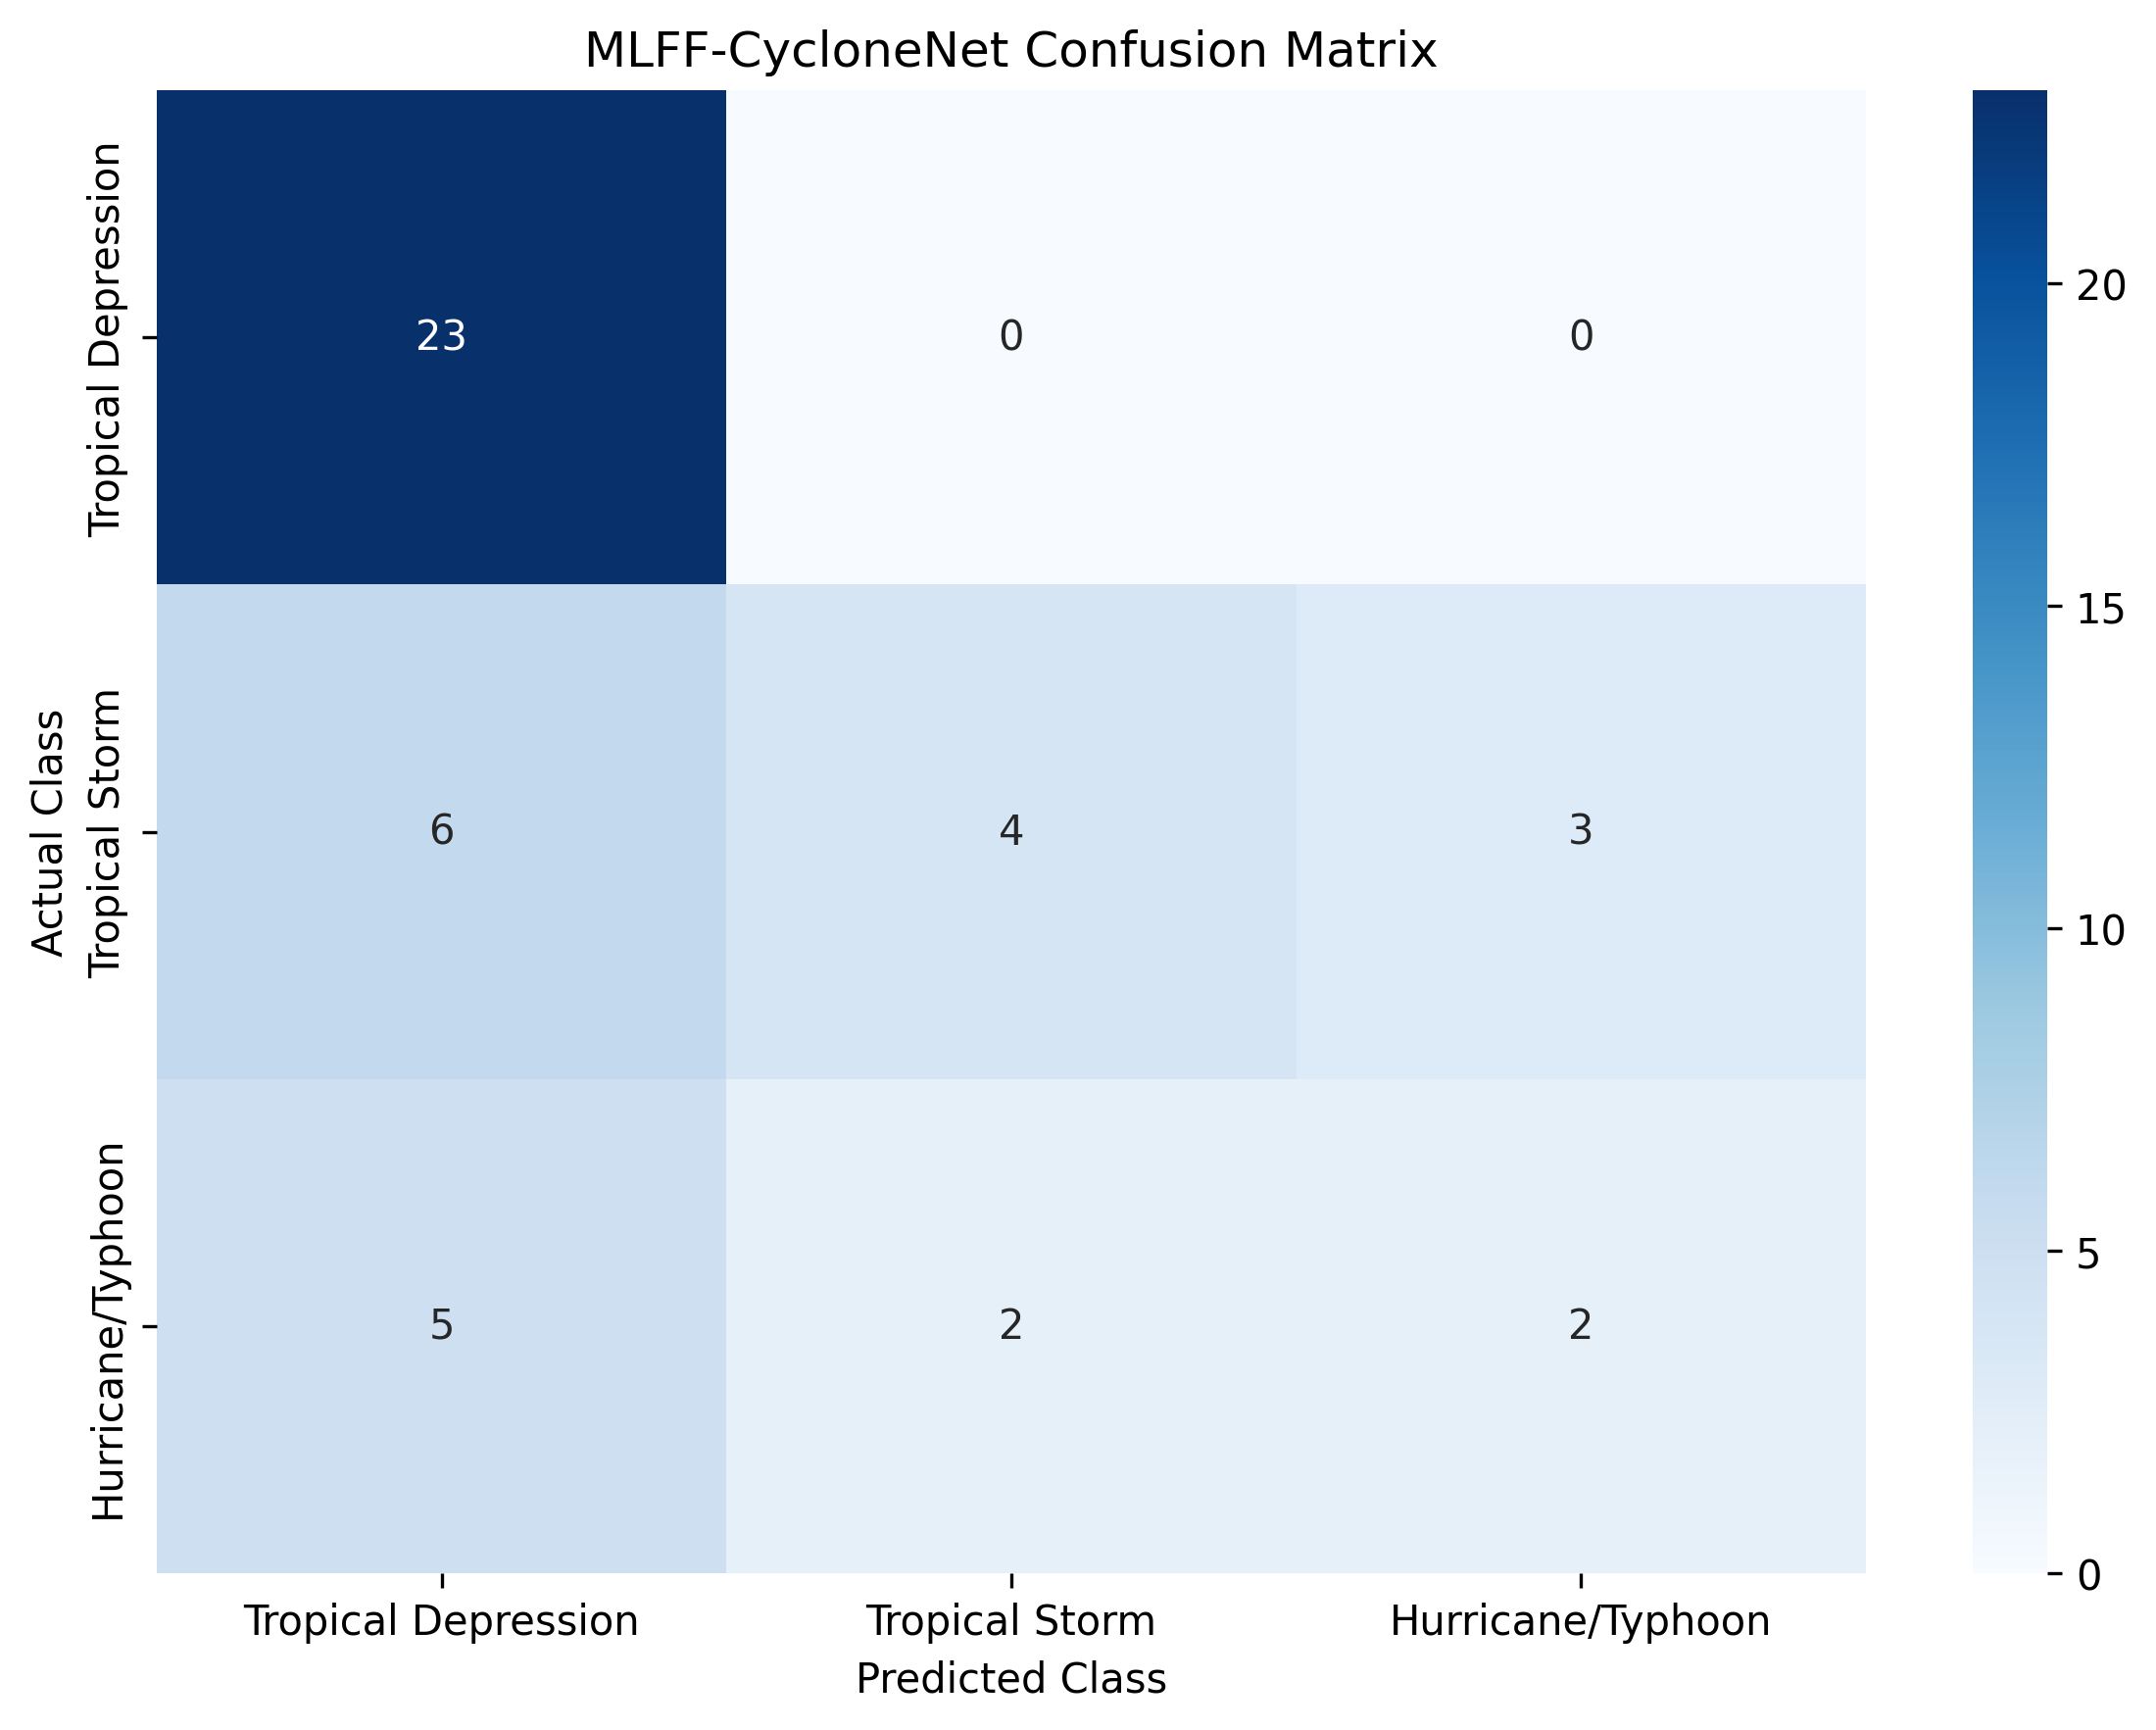

ACCURACY CURVE


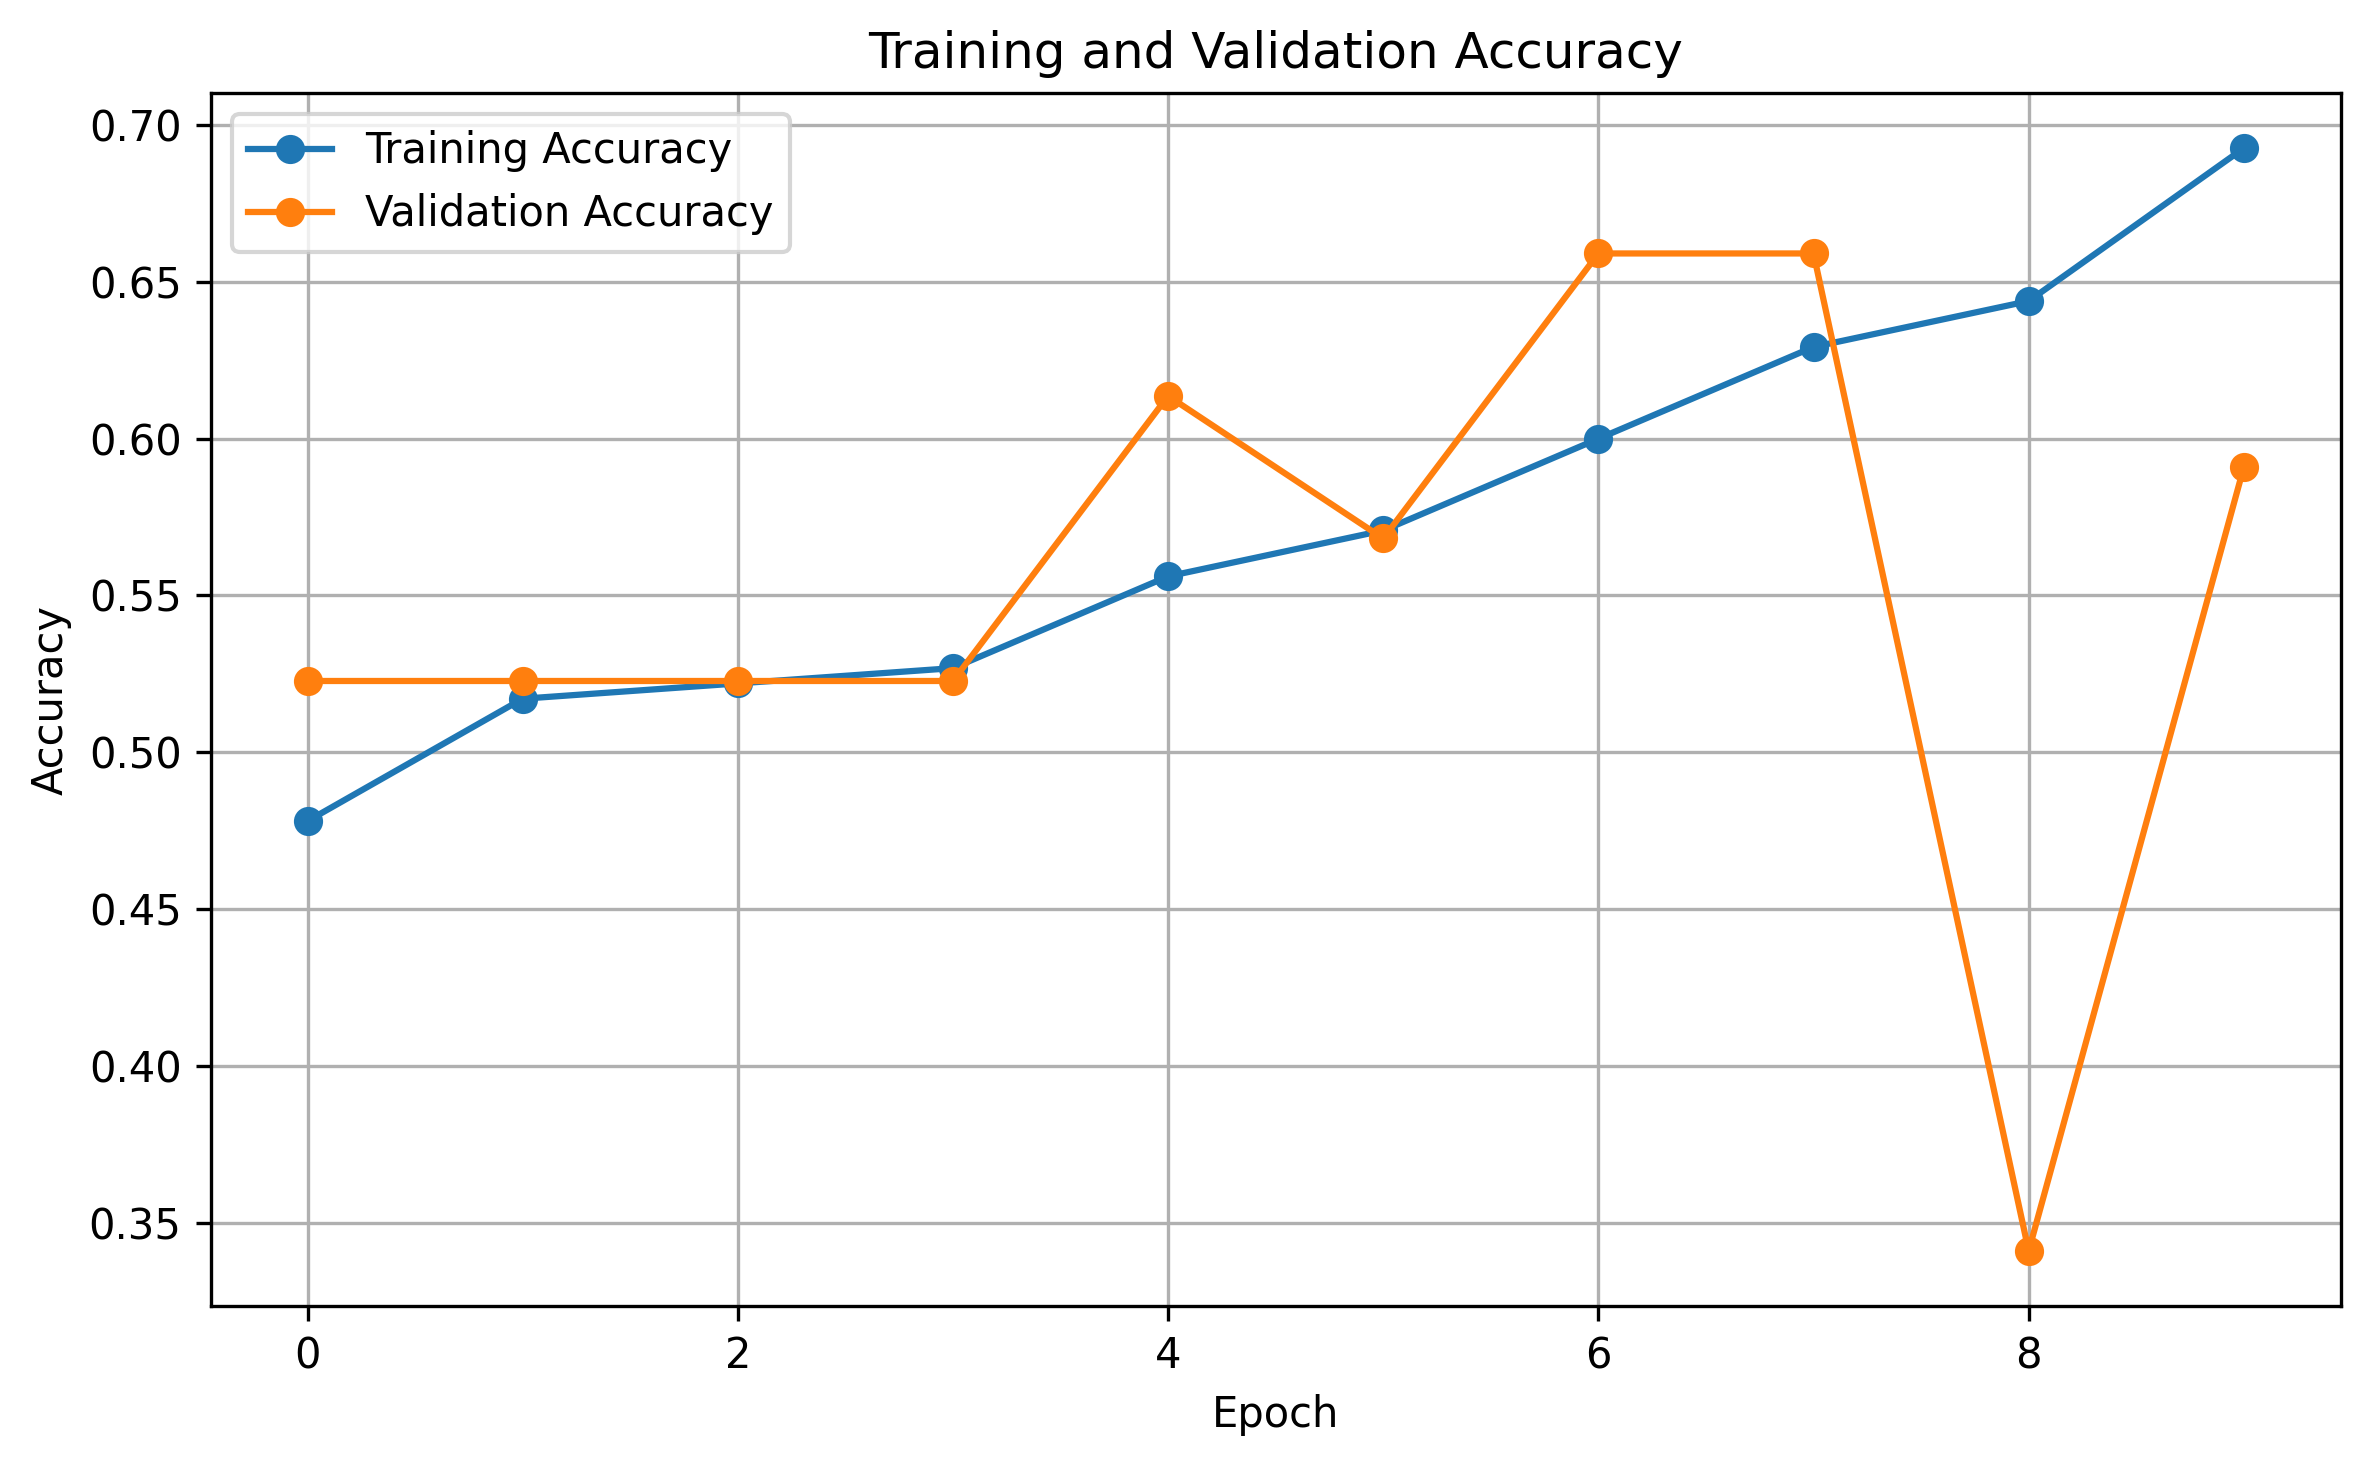

LOSS CURVE


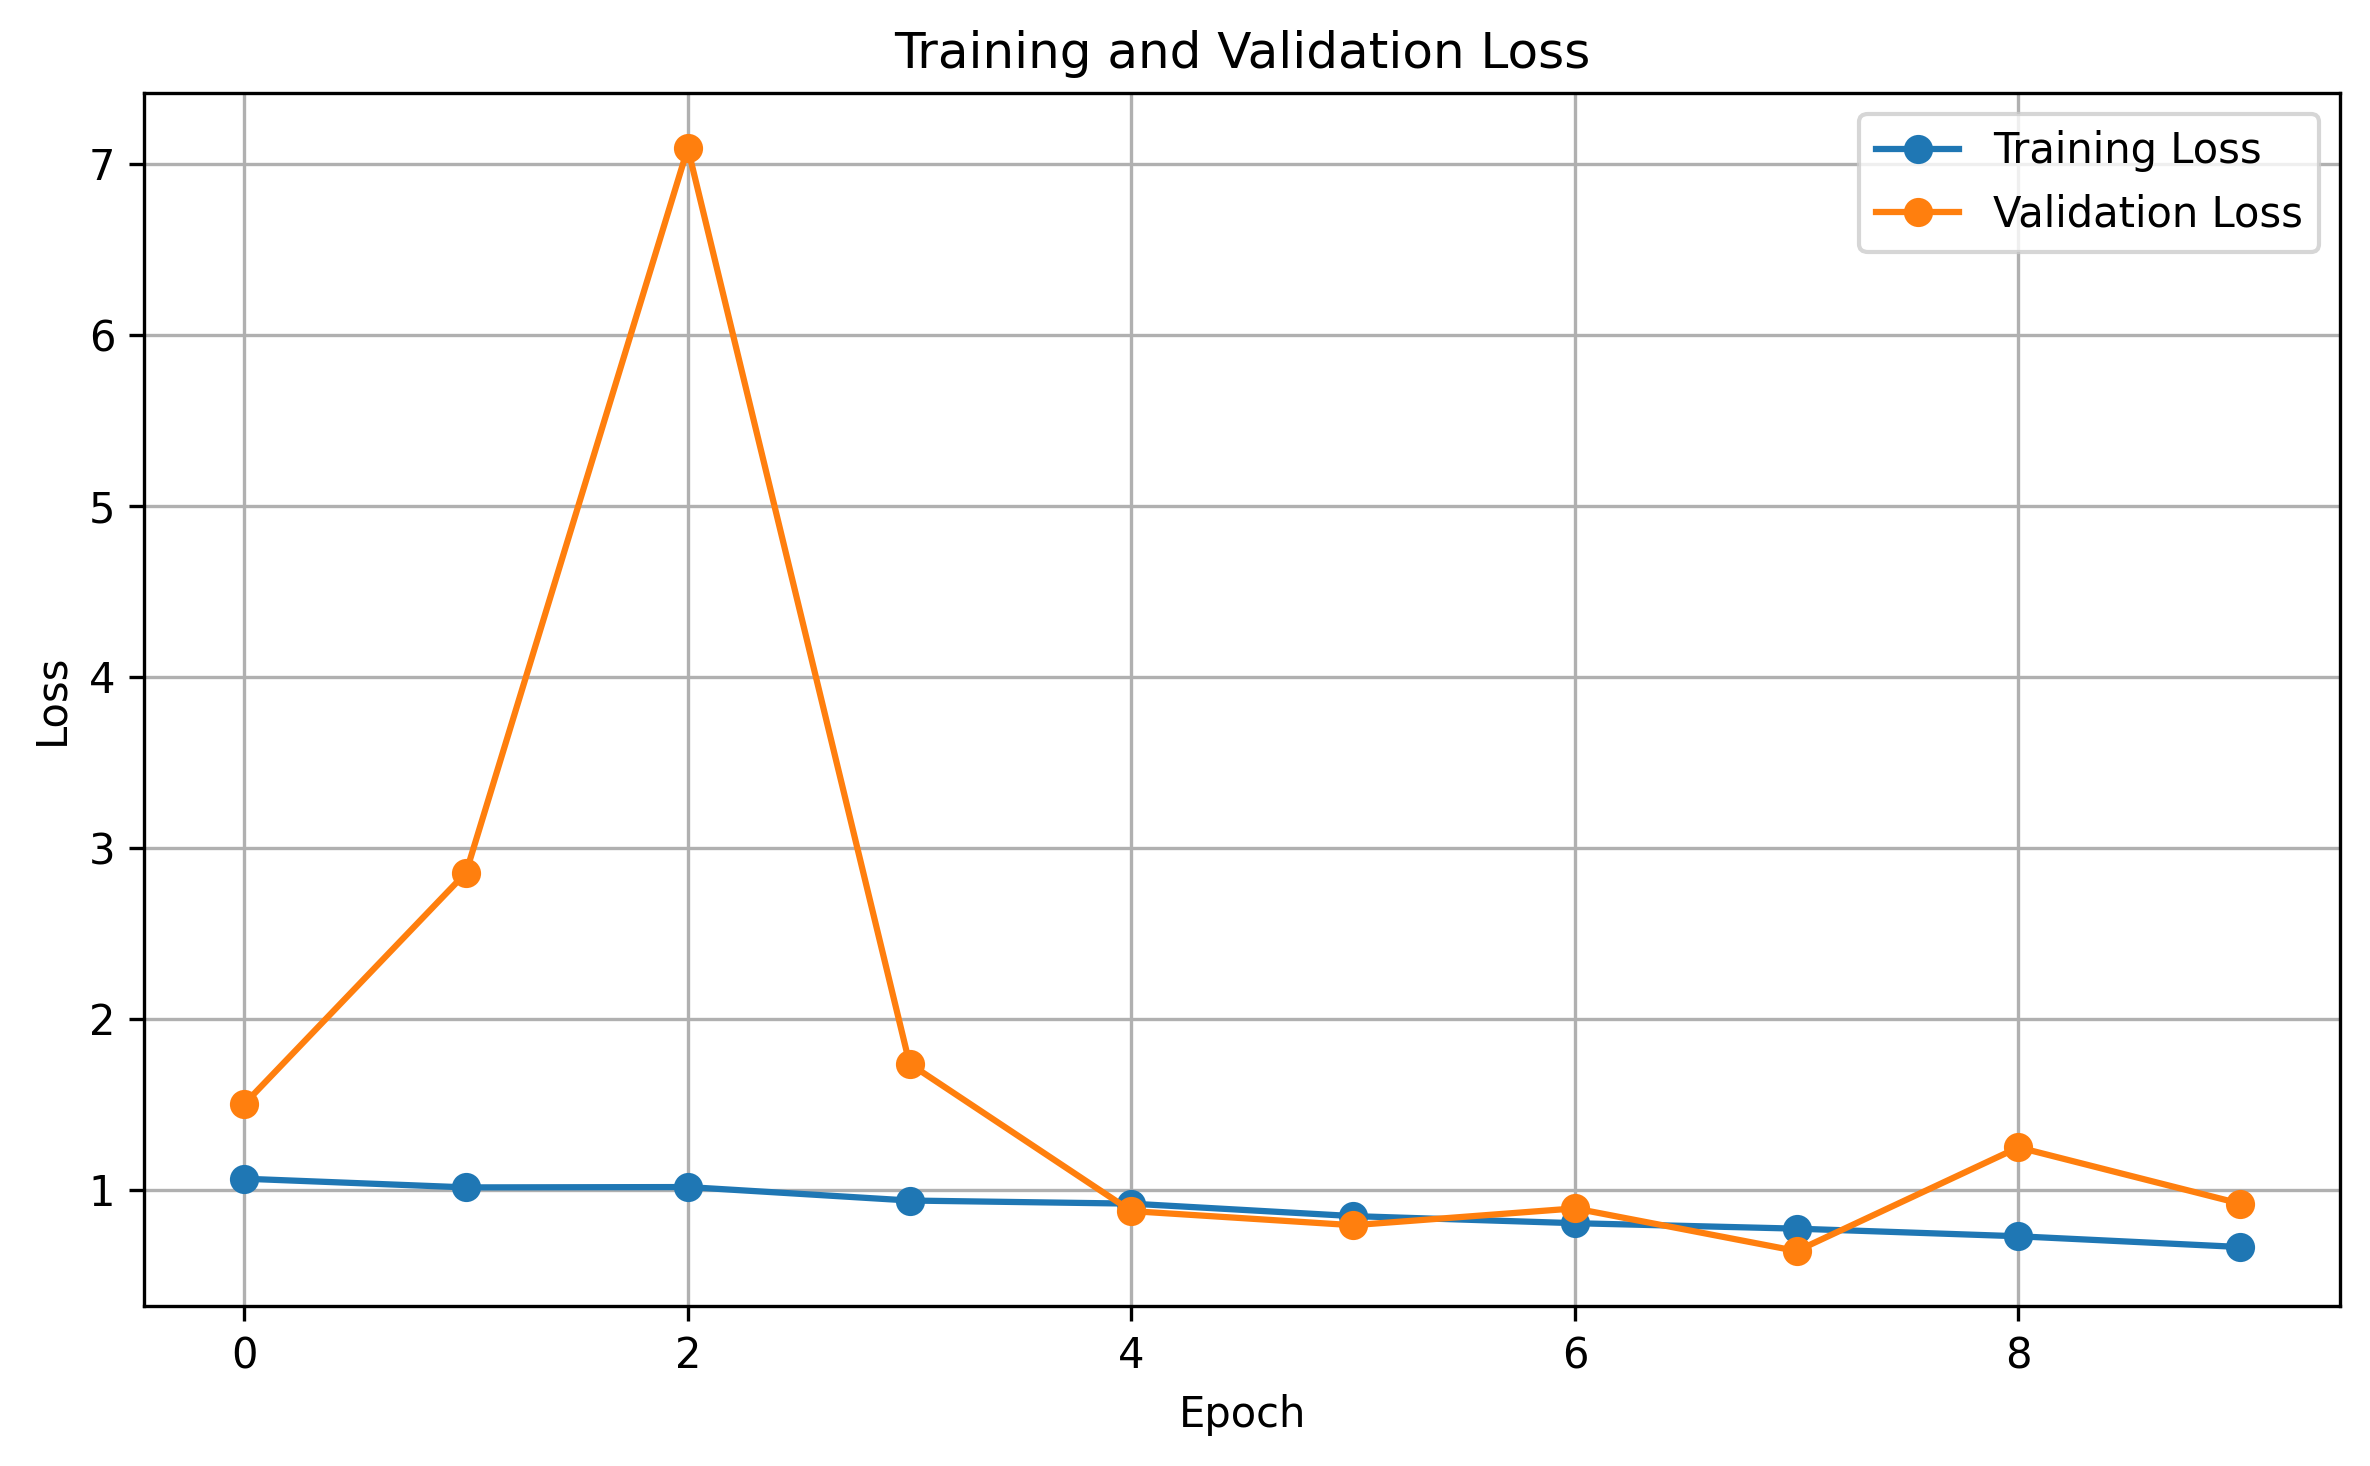

GRAD-CAM


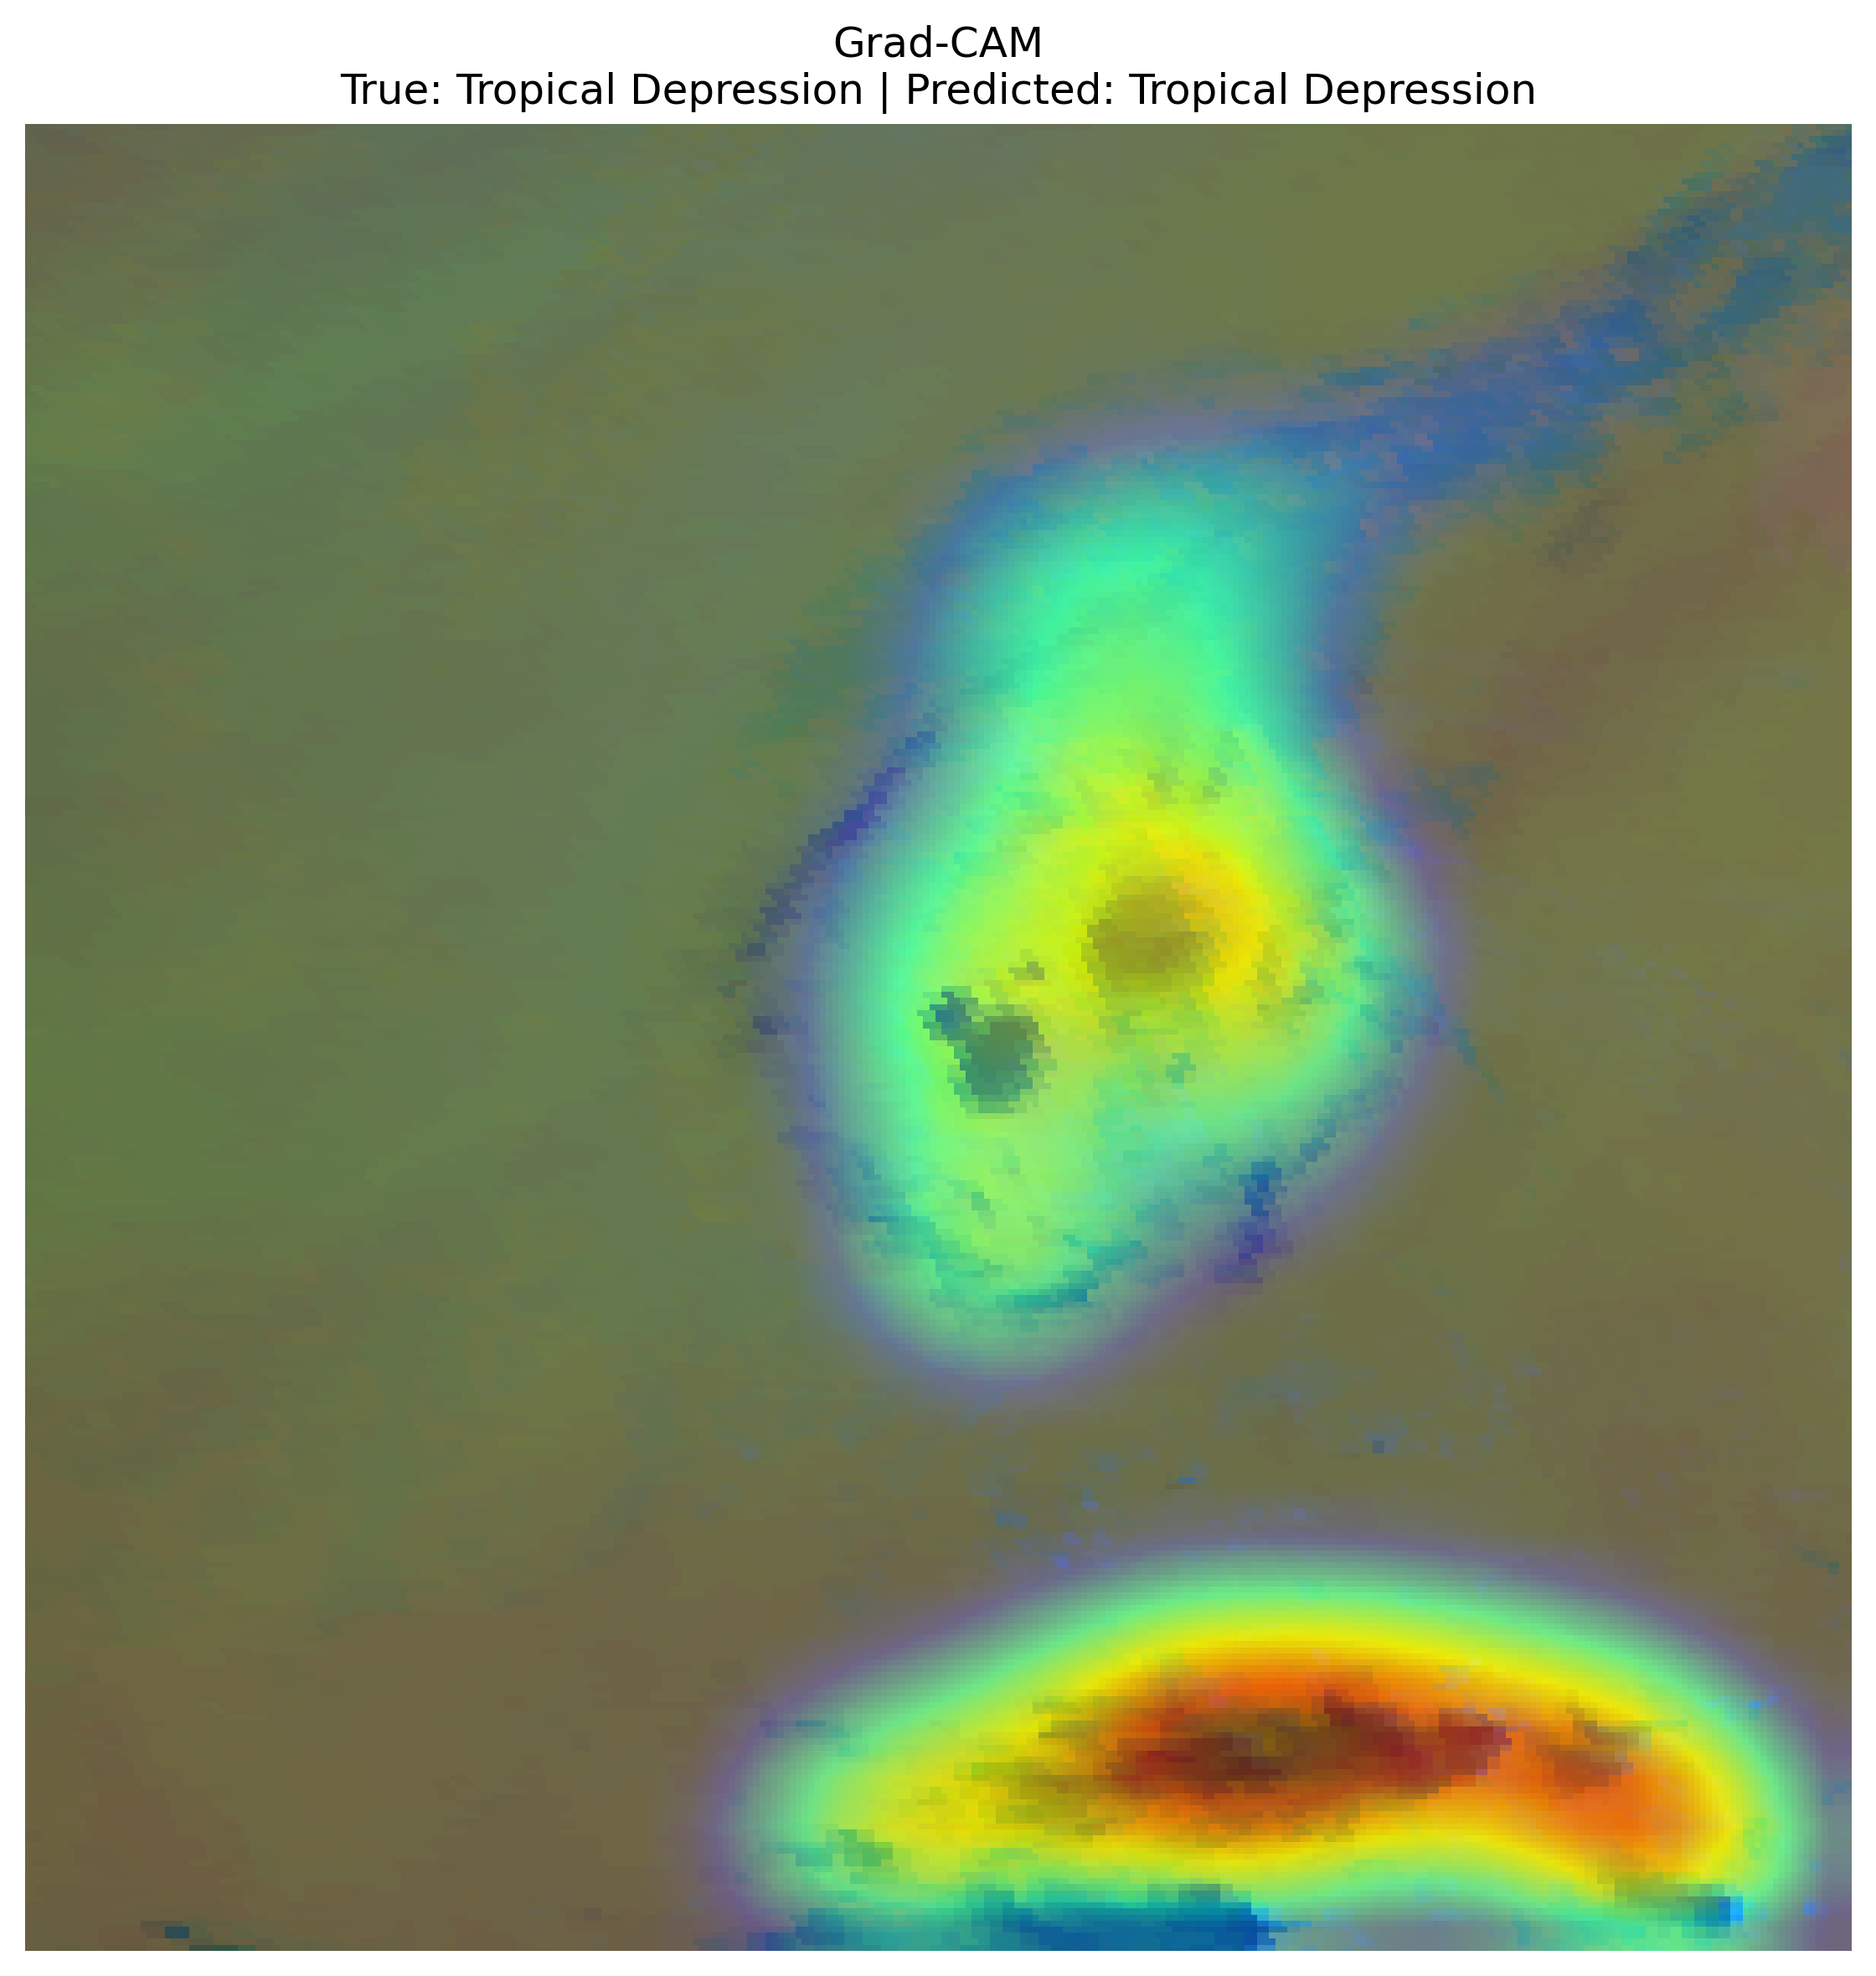

In [ ]:
from IPython.display import display, Image

print("CONFUSION MATRIX")
display(Image(filename=CM_PATH))

print("ACCURACY CURVE")
display(Image(filename=ACC_PATH))

print("LOSS CURVE")
display(Image(filename=LOSS_PATH))

print("GRAD-CAM")
display(Image(filename=GRADCAM_PATH))

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm

PROJECT_DIR = "/content/drive/MyDrive/Tropical_Cyclone_MLFF"

DETECTION_DIR = os.path.join(
    PROJECT_DIR, "data", "processed", "detection"
)

DETECTION_IMAGE_DIR = os.path.join(
    DETECTION_DIR, "images"
)

os.makedirs(DETECTION_IMAGE_DIR, exist_ok=True)

print("Detection dataset folder created:")
print(DETECTION_DIR)

Detection dataset folder created:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/detection


In [ ]:
import pandas as pd
import os

PROCESSED_CSV = os.path.join(
    PROJECT_DIR,
    "data",
    "processed",
    "processed_dataset.csv"
)

processed_df = pd.read_csv(PROCESSED_CSV)

print("Total cyclone samples:", len(processed_df))
print("\nColumns:")
print(processed_df.columns.tolist())

print("\nFirst 5 rows:")
display(processed_df.head())

Total cyclone samples: 294

Columns:
['array_path', 'storm', 'time', 'wind', 'pressure', 'label', 'class_name']

First 5 rows:


,array_path,storm,time,wind,pressure,label,class_name
0,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,2005-01-16T11:59:59.999959808,15.466667,1006.5,0,Tropical Depression
1,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,2005-01-16T11:59:59.999959808,15.466667,1006.5,0,Tropical Depression
2,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,2005-01-16T11:59:59.999959808,15.466667,1006.5,0,Tropical Depression
3,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,2005-01-16T14:59:59.999959808,16.933334,1006.0,0,Tropical Depression
4,/content/drive/MyDrive/Tropical_Cyclone_MLFF/d...,ERNEST,2005-01-16T14:59:59.999959808,16.933334,1006.0,0,Tropical Depression


In [ ]:
import numpy as np
import pandas as pd
import os

detection_records = []

sample_id = 0

for _, row in tqdm(
    processed_df.iterrows(),
    total=len(processed_df),
    desc="Creating detection samples"
):

    image = np.load(row["array_path"]).astype(np.float32)

    # ------------------------------------------------
    # POSITIVE SAMPLE: CYCLONE
    # ------------------------------------------------

    positive_path = os.path.join(
        DETECTION_IMAGE_DIR,
        f"sample_{sample_id:06d}.npy"
    )

    np.save(positive_path, image)

    detection_records.append({
        "array_path": positive_path,
        "storm": row["storm"],
        "time": row["time"],
        "detection_label": 1,
        "class_name": "Cyclone",
        "source": "cyclone_centered"
    })

    sample_id += 1

    # ------------------------------------------------
    # NEGATIVE SAMPLE: BACKGROUND / NO CYCLONE
    # ------------------------------------------------

    h, w = image.shape[1], image.shape[2]

    # Four corner/background regions
    patch_size = min(h, w) // 2

    patches = [
        image[:, 0:patch_size, 0:patch_size],
        image[:, 0:patch_size, w-patch_size:w],
        image[:, h-patch_size:h, 0:patch_size],
        image[:, h-patch_size:h, w-patch_size:w]
    ]

    # Select one deterministic background patch
    patch = patches[sample_id % len(patches)]

    negative_path = os.path.join(
        DETECTION_IMAGE_DIR,
        f"sample_{sample_id:06d}.npy"
    )

    np.save(negative_path, patch)

    detection_records.append({
        "array_path": negative_path,
        "storm": row["storm"],
        "time": row["time"],
        "detection_label": 0,
        "class_name": "No Cyclone",
        "source": "background_patch"
    })

    sample_id += 1

detection_df = pd.DataFrame(detection_records)

DETECTION_CSV = os.path.join(
    DETECTION_DIR,
    "detection_dataset.csv"
)

detection_df.to_csv(DETECTION_CSV, index=False)

print("Detection dataset created!")
print("Total samples:", len(detection_df))
print("\nClass distribution:")
print(detection_df["class_name"].value_counts())
print("\nSaved to:")
print(DETECTION_CSV)

Creating detection samples: 100%|██████████| 294/294 [00:17<00:00, 17.18it/s]

Detection dataset created!
Total samples: 588

Class distribution:
class_name
Cyclone       294
No Cyclone    294
Name: count, dtype: int64

Saved to:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/detection/detection_dataset.csv


In [ ]:
from sklearn.model_selection import train_test_split

# Load detection dataset
detection_df = pd.read_csv(DETECTION_CSV)

# First split: 70% train, 30% temporary
train_df, temp_df = train_test_split(
    detection_df,
    test_size=0.30,
    random_state=42,
    stratify=detection_df["detection_label"]
)

# Second split: 15% validation, 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["detection_label"]
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining distribution:")
print(train_df["class_name"].value_counts())

print("\nValidation distribution:")
print(val_df["class_name"].value_counts())

print("\nTesting distribution:")
print(test_df["class_name"].value_counts())

Training samples: 411
Validation samples: 88
Testing samples: 89

Training distribution:
class_name
Cyclone       206
No Cyclone    205
Name: count, dtype: int64

Validation distribution:
class_name
Cyclone       44
No Cyclone    44
Name: count, dtype: int64

Testing distribution:
class_name
No Cyclone    45
Cyclone       44
Name: count, dtype: int64


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import numpy as np

class CycloneDetectionDataset(Dataset):

    def __init__(self, dataframe, image_size=224):
        self.df = dataframe.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = np.load(row["array_path"]).astype(np.float32)

        # Channel-wise normalization
        for c in range(3):
            mean = image[c].mean()
            std = image[c].std()

            if std > 1e-6:
                image[c] = (image[c] - mean) / std
            else:
                image[c] = image[c] - mean

        # Convert to tensor
        image = torch.tensor(image, dtype=torch.float32)

        # Resize all images to the same size
        image = F.interpolate(
            image.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        label = torch.tensor(
            int(row["detection_label"]),
            dtype=torch.long
        )

        return image, label

In [ ]:
train_detection_dataset = CycloneDetectionDataset(
    train_df,
    image_size=224
)

val_detection_dataset = CycloneDetectionDataset(
    val_df,
    image_size=224
)

test_detection_dataset = CycloneDetectionDataset(
    test_df,
    image_size=224
)

train_detection_loader = DataLoader(
    train_detection_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_detection_loader = DataLoader(
    val_detection_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_detection_loader = DataLoader(
    test_detection_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Detection DataLoaders created successfully!")

images, labels = next(iter(train_detection_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Detection DataLoaders created successfully!
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Labels: tensor([0, 0, 1, 1, 1, 1, 0, 1, 0, 1])


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class DetectionConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DetectionChannelAttention(nn.Module):

    def __init__(self, channels):

        super().__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // 8, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // 8, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):

        attention = self.avg_pool(x)
        attention = self.fc(attention)

        return x * attention


class DetectionSpatialAttention(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv = nn.Conv2d(
            2,
            1,
            kernel_size=7,
            padding=3
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        avg_map = torch.mean(x, dim=1, keepdim=True)
        max_map, _ = torch.max(x, dim=1, keepdim=True)

        attention = torch.cat(
            [avg_map, max_map],
            dim=1
        )

        attention = self.sigmoid(
            self.conv(attention)
        )

        return x * attention


class MLFFCycloneDetector(nn.Module):

    def __init__(self):

        super().__init__()

        # Initial feature extraction
        self.stem = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2)
        )

        # Low-level features
        self.low_level = DetectionConvBlock(
            32,
            64
        )

        self.pool1 = nn.MaxPool2d(2)

        # Mid-level features
        self.mid_level = DetectionConvBlock(
            64,
            128
        )

        self.pool2 = nn.MaxPool2d(2)

        # High-level features
        self.high_level = DetectionConvBlock(
            128,
            256
        )

        # Projection layers
        self.low_projection = nn.Conv2d(
            64,
            256,
            kernel_size=1
        )

        self.mid_projection = nn.Conv2d(
            128,
            256,
            kernel_size=1
        )

        # Attention
        self.channel_attention = DetectionChannelAttention(256)
        self.spatial_attention = DetectionSpatialAttention()

        # Classification
        self.global_pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(

            nn.Linear(256, 128),

            nn.ReLU(inplace=True),

            nn.Dropout(0.4),

            nn.Linear(128, 2)
        )

    def forward(self, x):

        x = self.stem(x)

        # Low-level
        low = self.low_level(x)

        # Mid-level
        mid = self.mid_level(
            self.pool1(low)
        )

        # High-level
        high = self.high_level(
            self.pool2(mid)
        )

        # Project low and mid features
        low_proj = self.low_projection(low)

        mid_proj = self.mid_projection(mid)

        # Resize
        low_proj = F.interpolate(
            low_proj,
            size=high.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        mid_proj = F.interpolate(
            mid_proj,
            size=high.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # Multi-level feature fusion
        fused = (
            low_proj +
            mid_proj +
            high
        )

        # Attention
        fused = self.channel_attention(fused)
        fused = self.spatial_attention(fused)

        # Global pooling
        features = self.global_pool(fused)

        features = torch.flatten(
            features,
            1
        )

        # Binary classification
        output = self.classifier(features)

        return output

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

detector = MLFFCycloneDetector().to(device)

test_images, test_labels = next(
    iter(train_detection_loader)
)

test_images = test_images.to(device)

with torch.no_grad():
    output = detector(test_images)

print("Device:", device)
print("Input shape:", test_images.shape)
print("Output shape:", output.shape)

Device: cuda
Input shape: torch.Size([16, 3, 224, 224])
Output shape: torch.Size([16, 2])


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score
from tqdm import tqdm
import os
import json

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Create model
detector = MLFFCycloneDetector().to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    detector.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# Save directory
DETECTION_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

os.makedirs(DETECTION_MODEL_DIR, exist_ok=True)

BEST_DETECTOR_PATH = os.path.join(
    DETECTION_MODEL_DIR,
    "MLFF_CycloneDetector_best.pth"
)

print("Model ready!")
print("Best model will be saved to:")
print(BEST_DETECTOR_PATH)

Using device: cuda
Model ready!
Best model will be saved to:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/models/MLFF_CycloneDetector_best.pth


In [ ]:
def train_detection_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    predictions = []
    actuals = []

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        preds = torch.argmax(
            outputs,
            dim=1
        )

        predictions.extend(
            preds.detach().cpu().numpy()
        )

        actuals.extend(
            labels.detach().cpu().numpy()
        )

        progress.set_postfix(
            loss=loss.item()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        actuals,
        predictions
    )

    return epoch_loss, epoch_accuracy


def validate_detection_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    predictions = []
    actuals = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            preds = torch.argmax(
                outputs,
                dim=1
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            actuals.extend(
                labels.cpu().numpy()
            )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        actuals,
        predictions
    )

    return epoch_loss, epoch_accuracy

In [ ]:
NUM_EPOCHS = 10

history_detector = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_loss = float("inf")

for epoch in range(NUM_EPOCHS):

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS}"
    )
    print("-" * 50)

    train_loss, train_acc = train_detection_epoch(
        detector,
        train_detection_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_detection_epoch(
        detector,
        val_detection_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    # Save history
    history_detector["train_loss"].append(
        train_loss
    )

    history_detector["val_loss"].append(
        val_loss
    )

    history_detector["train_accuracy"].append(
        train_acc
    )

    history_detector["val_accuracy"].append(
        val_acc
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            detector.state_dict(),
            BEST_DETECTOR_PATH
        )

        print("✓ Best detector model saved!")


Epoch 1/10
--------------------------------------------------


Train Loss: 0.4401 | Train Accuracy: 0.8029
Val Loss: 0.3788 | Val Accuracy: 0.8182
✓ Best detector model saved!

Epoch 2/10
--------------------------------------------------


Train Loss: 0.2423 | Train Accuracy: 0.9051
Val Loss: 1.7739 | Val Accuracy: 0.5000

Epoch 3/10
--------------------------------------------------


Train Loss: 0.2010 | Train Accuracy: 0.9197
Val Loss: 0.1731 | Val Accuracy: 0.9432
✓ Best detector model saved!

Epoch 4/10
--------------------------------------------------


Train Loss: 0.1681 | Train Accuracy: 0.9367
Val Loss: 0.1177 | Val Accuracy: 0.9545
✓ Best detector model saved!

Epoch 5/10
--------------------------------------------------


...

Train Loss: 0.1622 | Train Accuracy: 0.9513
Val Loss: 0.2374 | Val Accuracy: 0.9205

Epoch 7/10
--------------------------------------------------


Train Loss: 0.1084 | Train Accuracy: 0.9586
Val Loss: 0.0921 | Val Accuracy: 0.9773
✓ Best detector model saved!

Epoch 8/10
--------------------------------------------------


Train Loss: 0.0920 | Train Accuracy: 0.9659
Val Loss: 0.1153 | Val Accuracy: 0.9659

Epoch 9/10
--------------------------------------------------


Train Loss: 0.0743 | Train Accuracy: 0.9757
Val Loss: 0.1084 | Val Accuracy: 0.9545

Epoch 10/10
--------------------------------------------------


Train Loss: 0.1141 | Train Accuracy: 0.9659
Val Loss: 0.0634 | Val Accuracy: 0.9773
✓ Best detector model saved!


In [ ]:
# Load the best saved detector
detector.load_state_dict(
    torch.load(
        BEST_DETECTOR_PATH,
        map_location=device
    )
)

detector.to(device)
detector.eval()

print("Best MLFF Cyclone Detector loaded successfully!")

Best MLFF Cyclone Detector loaded successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(
        test_detection_loader,
        desc="Testing"
    ):

        images = images.to(device)

        outputs = detector(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

# Convert to arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
all_probabilities = np.array(all_probabilities)

print("Testing completed!")
print("Number of test samples:", len(all_labels))

Testing: 100%|██████████| 6/6 [00:00<00:00,  8.62it/s]

Testing completed!
Number of test samples: 89


In [ ]:
detection_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

detection_precision = precision_score(
    all_labels,
    all_predictions,
    average="binary",
    zero_division=0
)

detection_recall = recall_score(
    all_labels,
    all_predictions,
    average="binary",
    zero_division=0
)

detection_f1 = f1_score(
    all_labels,
    all_predictions,
    average="binary",
    zero_division=0
)

print("\n===== MLFF CYCLONE DETECTOR RESULTS =====")

print(
    f"Accuracy  : {detection_accuracy:.4f}"
)

print(
    f"Precision : {detection_precision:.4f}"
)

print(
    f"Recall    : {detection_recall:.4f}"
)

print(
    f"F1 Score  : {detection_f1:.4f}"
)

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "No Cyclone",
            "Cyclone"
        ],
        zero_division=0
    )
)


===== MLFF CYCLONE DETECTOR RESULTS =====
Accuracy  : 0.9888
Precision : 1.0000
Recall    : 0.9773
F1 Score  : 0.9885

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

  No Cyclone       0.98      1.00      0.99        45
     Cyclone       1.00      0.98      0.99        44

    accuracy                           0.99        89
   macro avg       0.99      0.99      0.99        89
weighted avg       0.99      0.99      0.99        89



Confusion Matrix:
[[45  0]
 [ 1 43]]


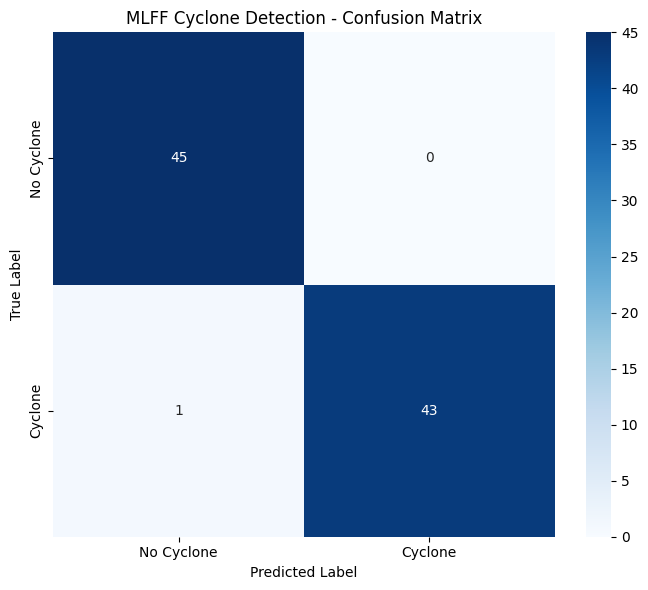

Saved: /content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/detection_confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Cyclone",
        "Cyclone"
    ],
    yticklabels=[
        "No Cyclone",
        "Cyclone"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MLFF Cyclone Detection - Confusion Matrix")

plt.tight_layout()

DETECTION_CM_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "detection_confusion_matrix.png"
)

os.makedirs(
    os.path.dirname(DETECTION_CM_PATH),
    exist_ok=True
)

plt.savefig(
    DETECTION_CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", DETECTION_CM_PATH)

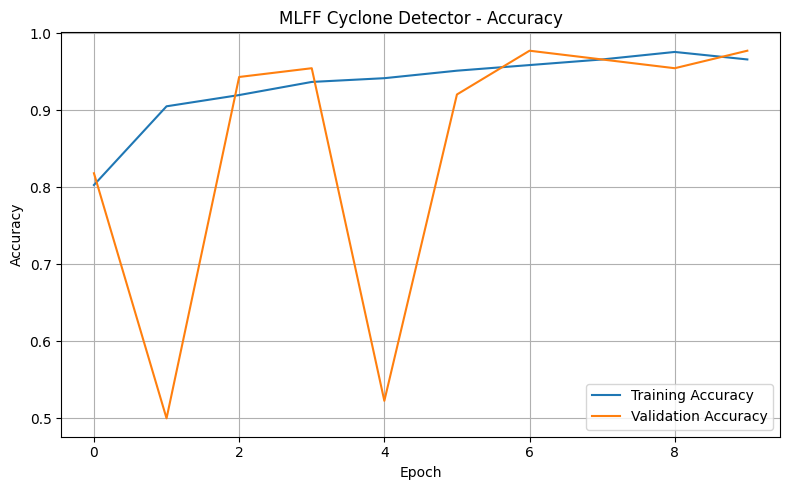

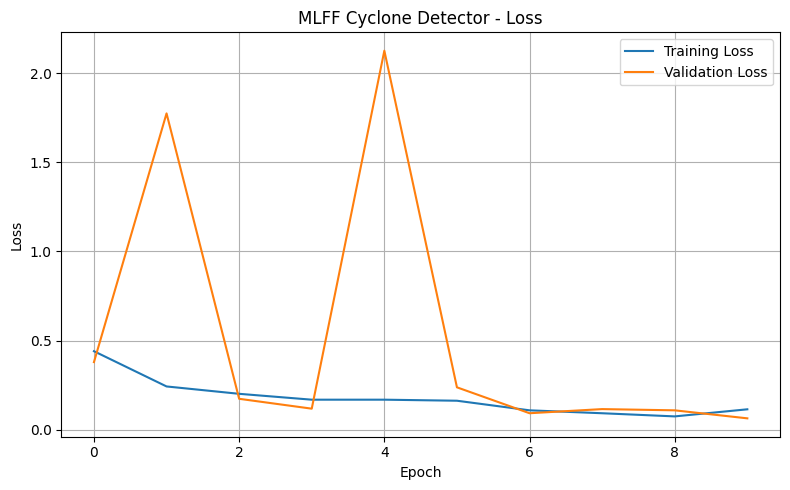

Detection curves saved successfully!


In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_detector["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_detector["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLFF Cyclone Detector - Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()

DETECTION_ACC_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "detection_accuracy_curve.png"
)

plt.savefig(
    DETECTION_ACC_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history_detector["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_detector["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLFF Cyclone Detector - Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

DETECTION_LOSS_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "detection_loss_curve.png"
)

plt.savefig(
    DETECTION_LOSS_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Detection curves saved successfully!")

In [ ]:
detection_results = {
    "accuracy": float(detection_accuracy),
    "precision": float(detection_precision),
    "recall": float(detection_recall),
    "f1_score": float(detection_f1),
    "test_samples": int(len(all_labels))
}

DETECTION_RESULTS_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "detection_metrics.json"
)

with open(
    DETECTION_RESULTS_PATH,
    "w"
) as f:

    json.dump(
        detection_results,
        f,
        indent=4
    )

HISTORY_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "detection_training_history.json"
)

with open(
    HISTORY_PATH,
    "w"
) as f:

    json.dump(
        history_detector,
        f,
        indent=4
    )

print("Detection metrics saved to:")
print(DETECTION_RESULTS_PATH)

print("\nTraining history saved to:")
print(HISTORY_PATH)

Detection metrics saved to:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/detection_metrics.json

Training history saved to:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/detection_training_history.json


In [ ]:
# ============================================
# CELL 18 - LOAD CLASSIFICATION MODEL
# ============================================

CLASSIFIER_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "MLFF_CycloneNet_best.pth"
)

# Create the same model architecture
classifier = MLFFCycloneNet(
    num_classes=3
).to(device)

# Load checkpoint
checkpoint = torch.load(
    CLASSIFIER_PATH,
    map_location=device
)

# Check what was saved
print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:")
    print(checkpoint.keys())

# Extract model weights
if "model_state_dict" in checkpoint:

    classifier.load_state_dict(
        checkpoint["model_state_dict"]
    )

else:

    classifier.load_state_dict(
        checkpoint
    )

classifier.to(device)
classifier.eval()

print("\nMLFF-CycloneNet classifier loaded successfully!")
print("Classifier path:")
print(CLASSIFIER_PATH)

Checkpoint type: <class 'dict'>
Checkpoint keys:
dict_keys(['model_state_dict', 'num_classes', 'class_names', 'best_val_loss'])

MLFF-CycloneNet classifier loaded successfully!
Classifier path:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/models/MLFF_CycloneNet_best.pth


In [ ]:
import torch.nn.functional as F

classification_names = {
    0: "Tropical Depression",
    1: "Tropical Storm",
    2: "Hurricane/Typhoon"
}

def prepare_image_for_model(image, image_size=224):

    image = image.astype(np.float32)

    # Channel-wise normalization
    for c in range(3):

        mean = image[c].mean()
        std = image[c].std()

        if std > 1e-6:
            image[c] = (
                image[c] - mean
            ) / std
        else:
            image[c] = image[c] - mean

    image = torch.tensor(
        image,
        dtype=torch.float32
    )

    # Add batch dimension
    image = image.unsqueeze(0)

    # Resize
    image = F.interpolate(
        image,
        size=(image_size, image_size),
        mode="bilinear",
        align_corners=False
    )

    return image


def predict_cyclone(image_path):

    # Load satellite image
    image = np.load(image_path).astype(
        np.float32
    )

    # ------------------------------------------------
    # STAGE 1: CYCLONE DETECTION
    # ------------------------------------------------

    detector_input = prepare_image_for_model(
        image,
        image_size=224
    ).to(device)

    with torch.no_grad():

        detector_output = detector(
            detector_input
        )

        detector_probability = torch.softmax(
            detector_output,
            dim=1
        )

        detector_prediction = torch.argmax(
            detector_probability,
            dim=1
        ).item()

    detection_confidence = (
        detector_probability[0]
        [detector_prediction]
        .item()
    )

    # No cyclone detected
    if detector_prediction == 0:

        return {
            "detection": "No Cyclone",
            "detection_confidence":
                detection_confidence,
            "classification": None,
            "classification_confidence": None
        }

    # ------------------------------------------------
    # STAGE 2: CYCLONE CLASSIFICATION
    # ------------------------------------------------

    classifier_input = prepare_image_for_model(
        image,
        image_size=224
    ).to(device)

    with torch.no_grad():

        classifier_output = classifier(
            classifier_input
        )

        classifier_probability = torch.softmax(
            classifier_output,
            dim=1
        )

        classifier_prediction = torch.argmax(
            classifier_probability,
            dim=1
        ).item()

    classification_confidence = (
        classifier_probability[0]
        [classifier_prediction]
        .item()
    )

    return {
        "detection": "Cyclone",
        "detection_confidence":
            detection_confidence,

        "classification":
            classification_names[
                classifier_prediction
            ],

        "classification_confidence":
            classification_confidence
    }

print("Complete detection + classification pipeline created!")

Complete detection + classification pipeline created!


In [ ]:
# Select one test sample

sample_path = test_df.iloc[0]["array_path"]

result = predict_cyclone(
    sample_path
)

print("===== CYCLONE ANALYSIS =====")

print(
    "Detection:",
    result["detection"]
)

print(
    "Detection Confidence:",
    f"{result['detection_confidence'] * 100:.2f}%"
)

if result["classification"] is not None:

    print(
        "Classification:",
        result["classification"]
    )

    print(
        "Classification Confidence:",
        f"{result['classification_confidence'] * 100:.2f}%"
    )

===== CYCLONE ANALYSIS =====
Detection: Cyclone
Detection Confidence: 90.09%
Classification: Tropical Depression
Classification Confidence: 99.62%


In [ ]:
print("===== TESTING COMPLETE PIPELINE =====\n")

for i in range(10):

    sample = test_df.iloc[i]

    result = predict_cyclone(
        sample["array_path"]
    )

    print(
        f"Sample {i + 1}"
    )

    print(
        "Actual Detection:",
        sample["class_name"]
    )

    print(
        "Predicted Detection:",
        result["detection"]
    )

    print(
        "Detection Confidence:",
        f"{result['detection_confidence'] * 100:.2f}%"
    )

    if result["classification"]:

        print(
            "Predicted Class:",
            result["classification"]
        )

        print(
            "Classification Confidence:",
            f"{result['classification_confidence'] * 100:.2f}%"
        )

    print("-" * 50)

===== TESTING COMPLETE PIPELINE =====

Sample 1
Actual Detection: Cyclone
Predicted Detection: Cyclone
Detection Confidence: 90.09%
Predicted Class: Tropical Depression
Classification Confidence: 99.62%
--------------------------------------------------
Sample 2
Actual Detection: Cyclone
Predicted Detection: Cyclone
Detection Confidence: 96.82%
Predicted Class: Hurricane/Typhoon
Classification Confidence: 43.85%
--------------------------------------------------
Sample 3
Actual Detection: No Cyclone
Predicted Detection: No Cyclone
Detection Confidence: 99.62%
--------------------------------------------------
Sample 4
Actual Detection: No Cyclone
Predicted Detection: No Cyclone
Detection Confidence: 96.63%
--------------------------------------------------
Sample 5
Actual Detection: No Cyclone
Predicted Detection: No Cyclone
Detection Confidence: 99.07%
--------------------------------------------------
Sample 6
Actual Detection: No Cyclone
Predicted Detection: No Cyclone
Detection Con

In [ ]:
PIPELINE_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "MLFF_Cyclone_Complete_Pipeline.pth"
)

torch.save(
    {
        "detector_state_dict":
            detector.state_dict(),

        "classifier_state_dict":
            classifier.state_dict(),

        "detection_classes": {
            0: "No Cyclone",
            1: "Cyclone"
        },

        "classification_classes":
            classification_names
    },
    PIPELINE_PATH
)

print("Complete MLFF cyclone pipeline saved!")
print(PIPELINE_PATH)

Complete MLFF cyclone pipeline saved!
/content/drive/MyDrive/Tropical_Cyclone_MLFF/models/MLFF_Cyclone_Complete_Pipeline.pth


In [ ]:
# ============================================
# FINAL MLFF CYCLONE PREDICTION DEMO
# ============================================

# Select a sample from the test dataset
sample_index = 0

sample_path = test_df.iloc[sample_index]["array_path"]

result = predict_cyclone(sample_path)

print("\n")
print("=" * 55)
print("        MLFF TROPICAL CYCLONE ANALYSIS")
print("=" * 55)

print(f"\nInput file:")
print(sample_path)

print("\n--- STAGE 1: CYCLONE DETECTION ---")

print(
    f"Result: {result['detection']}"
)

print(
    f"Confidence: "
    f"{result['detection_confidence'] * 100:.2f}%"
)

if result["detection"] == "Cyclone":

    print("\n--- STAGE 2: CYCLONE CLASSIFICATION ---")

    print(
        f"Intensity Class: "
        f"{result['classification']}"
    )

    print(
        f"Confidence: "
        f"{result['classification_confidence'] * 100:.2f}%"
    )

else:

    print(
        "\nClassification skipped because "
        "no cyclone was detected."
    )

print("\n" + "=" * 55)



        MLFF TROPICAL CYCLONE ANALYSIS

Input file:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/data/processed/detection/images/sample_000524.npy

--- STAGE 1: CYCLONE DETECTION ---
Result: Cyclone
Confidence: 90.09%

--- STAGE 2: CYCLONE CLASSIFICATION ---
Intensity Class: Tropical Depression
Confidence: 99.62%



In [ ]:
demo_results = []

num_samples = min(20, len(test_df))

for i in range(num_samples):

    row = test_df.iloc[i]

    result = predict_cyclone(
        row["array_path"]
    )

    demo_results.append({
        "Sample": i + 1,
        "Actual": row["class_name"],
        "Predicted Detection": result["detection"],
        "Detection Confidence":
            round(
                result["detection_confidence"] * 100,
                2
            ),
        "Predicted Classification":
            result["classification"]
            if result["classification"] is not None
            else "-"
    })

demo_df = pd.DataFrame(demo_results)

display(demo_df)

,Sample,Actual,Predicted Detection,Detection Confidence,Predicted Classification
0,1,Cyclone,Cyclone,90.09,Tropical Depression
1,2,Cyclone,Cyclone,96.82,Hurricane/Typhoon
2,3,No Cyclone,No Cyclone,99.62,-
3,4,No Cyclone,No Cyclone,96.63,-
4,5,No Cyclone,No Cyclone,99.07,-
5,6,No Cyclone,No Cyclone,99.46,-
6,7,No Cyclone,No Cyclone,93.82,-
7,8,Cyclone,Cyclone,91.69,Tropical Depression
8,9,No Cyclone,No Cyclone,99.20,-
9,10,No Cyclone,No Cyclone,91.99,-


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt

# IMPORTANT:
# Use the final convolution layer, not BatchNorm.
target_layers = [
    classifier.level3.conv3.block[3]
]

print("Grad-CAM target layer selected.")

Grad-CAM target layer selected.


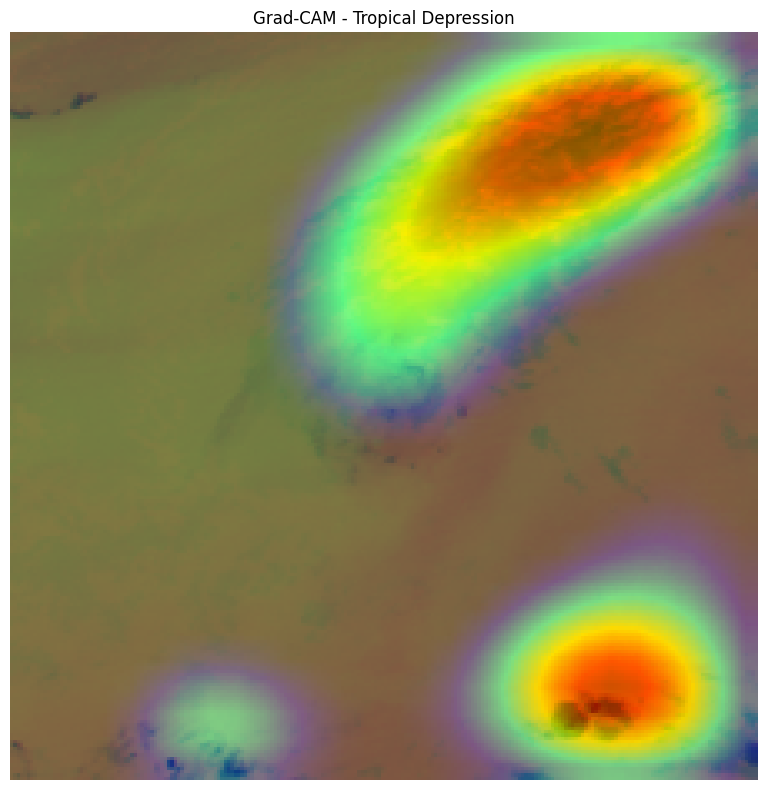

Predicted class:
Tropical Depression
Confidence: 99.62%

Grad-CAM saved to:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/gradcam_classifier.png


In [ ]:
# Select a cyclone sample from the test dataset
cyclone_samples = test_df[
    test_df["detection_label"] == 1
]

sample_path = cyclone_samples.iloc[0]["array_path"]

# Load original satellite data
image = np.load(sample_path).astype(np.float32)

# Prepare input
input_tensor = prepare_image_for_model(
    image,
    image_size=224
).to(device)

# Get classifier prediction
with torch.no_grad():

    output = classifier(input_tensor)

    probabilities = torch.softmax(
        output,
        dim=1
    )

    predicted_class = torch.argmax(
        probabilities,
        dim=1
    ).item()

# Grad-CAM
target = [
    ClassifierOutputTarget(predicted_class)
]

with GradCAM(
    model=classifier,
    target_layers=target_layers
) as cam:

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=target
    )[0]

# Create a display image
display_image = image.copy()

# Normalize each channel for visualization
for c in range(3):

    channel = display_image[c]

    channel_min = channel.min()
    channel_max = channel.max()

    if channel_max > channel_min:

        display_image[c] = (
            (channel - channel_min) /
            (channel_max - channel_min)
        )

# Convert CHW -> HWC
display_image = np.transpose(
    display_image,
    (1, 2, 0)
)

# Resize to match Grad-CAM
display_image = np.array(
    Image.fromarray(
        (display_image * 255).astype(np.uint8)
    ).resize((224, 224))
) / 255.0

# Generate heatmap overlay
visualization = show_cam_on_image(
    display_image,
    grayscale_cam,
    use_rgb=True
)

# Display
plt.figure(figsize=(8, 8))

plt.imshow(visualization)

plt.axis("off")

plt.title(
    f"Grad-CAM - {classification_names[predicted_class]}"
)

plt.tight_layout()

GRADCAM_PATH = os.path.join(
    PROJECT_DIR,
    "outputs",
    "gradcam_classifier.png"
)

plt.savefig(
    GRADCAM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Predicted class:")
print(classification_names[predicted_class])

print(
    f"Confidence: "
    f"{probabilities[0, predicted_class].item() * 100:.2f}%"
)

print("\nGrad-CAM saved to:")
print(GRADCAM_PATH)

In [ ]:
import json
import os
import pandas as pd

OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

# Load detection metrics
detection_metrics_path = os.path.join(
    OUTPUT_DIR, "detection_metrics.json"
)

with open(detection_metrics_path, "r") as f:
    detection_metrics = json.load(f)

# Load classification metrics
classification_metrics_path = os.path.join(
    OUTPUT_DIR, "evaluation_metrics.json"
)

with open(classification_metrics_path, "r") as f:
    classification_metrics = json.load(f)

print("=" * 60)
print("MLFF-CycloneNet FINAL EVALUATION")
print("=" * 60)

print("\n1. CYCLONE DETECTION")
print("-" * 40)

for key, value in detection_metrics.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

print("\n2. CYCLONE INTENSITY CLASSIFICATION")
print("-" * 40)

for key, value in classification_metrics.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

print("\nEvaluation summary completed!")

MLFF-CycloneNet FINAL EVALUATION

1. CYCLONE DETECTION
----------------------------------------
accuracy: 0.9888
precision: 1.0000
recall: 0.9773
f1_score: 0.9885
test_samples: 89.0000

2. CYCLONE INTENSITY CLASSIFICATION
----------------------------------------
accuracy: 0.6444
precision: 0.6183
recall: 0.6444
f1_score: 0.5913
num_classes: 3.0000

Evaluation summary completed!


In [ ]:
final_results = []

# Detection results
for key, value in detection_metrics.items():
    if isinstance(value, (int, float)):
        final_results.append({
            "Task": "Cyclone Detection",
            "Metric": key,
            "Value": value
        })

# Classification results
for key, value in classification_metrics.items():
    if isinstance(value, (int, float)):
        final_results.append({
            "Task": "Intensity Classification",
            "Metric": key,
            "Value": value
        })

final_results_df = pd.DataFrame(final_results)

display(final_results_df)

# Save
final_results_path = os.path.join(
    OUTPUT_DIR,
    "final_evaluation_summary.csv"
)

final_results_df.to_csv(final_results_path, index=False)

print("\nSaved:")
print(final_results_path)

,Task,Metric,Value
0,Cyclone Detection,accuracy,0.988764
1,Cyclone Detection,precision,1.000000
2,Cyclone Detection,recall,0.977273
3,Cyclone Detection,f1_score,0.988506
4,Cyclone Detection,test_samples,89.000000
5,Intensity Classification,accuracy,0.644444
6,Intensity Classification,precision,0.618344
7,Intensity Classification,recall,0.644444
8,Intensity Classification,f1_score,0.591256
9,Intensity Classification,num_classes,3.000000



Saved:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/final_evaluation_summary.csv


In [ ]:
summary = {
    "project": "Artificial Intelligence / Machine Learning Based Tropical Cyclone Identification and Classification",
    "model": "MLFF-CycloneNet",
    "dataset": "NOAA HURSAT-B1 v06",
    "input_channels": [
        "IRWIN",
        "IRWVP",
        "VSCHN"
    ],
    "architecture": [
        "Convolutional Feature Extraction",
        "Low-Level Features",
        "Mid-Level Features",
        "High-Level Features",
        "Multi-Level Feature Fusion",
        "Channel Attention",
        "Spatial Attention",
        "Global Average Pooling",
        "Softmax Classification"
    ],
    "tasks": [
        "Cyclone Detection",
        "Cyclone Intensity Classification"
    ],
    "classification_classes": [
        "Tropical Depression",
        "Tropical Storm",
        "Hurricane/Typhoon"
    ],
    "outputs": {
        "best_classifier": os.path.join(
            PROJECT_DIR,
            "models",
            "MLFF_CycloneNet_best.pth"
        ),
        "best_detector": os.path.join(
            PROJECT_DIR,
            "models",
            "MLFF_CycloneDetector_best.pth"
        ),
        "complete_pipeline": os.path.join(
            PROJECT_DIR,
            "models",
            "MLFF_Cyclone_Complete_Pipeline.pth"
        ),
        "evaluation_summary": final_results_path,
        "gradcam": os.path.join(
            OUTPUT_DIR,
            "gradcam_classifier.png"
        )
    }
}

summary_path = os.path.join(
    OUTPUT_DIR,
    "MLFF_CycloneNet_project_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("Project summary saved:")
print(summary_path)

Project summary saved:
/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/MLFF_CycloneNet_project_summary.json


In [ ]:
import os
import json

OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

# Load saved metrics
with open(os.path.join(OUTPUT_DIR, "detection_metrics.json"), "r") as f:
    detection_metrics = json.load(f)

with open(os.path.join(OUTPUT_DIR, "evaluation_metrics.json"), "r") as f:
    classification_metrics = json.load(f)

def format_metrics(metrics):
    text = ""
    for key, value in metrics.items():
        if isinstance(value, (int, float)):
            text += f"- {key}: {value:.4f}\n"
    return text

report = f"""
============================================================
MLFF-CycloneNet
TROPICAL CYCLONE IDENTIFICATION AND CLASSIFICATION
USING MULTI-CHANNEL SATELLITE DATA
============================================================

1. ABSTRACT
------------------------------------------------------------
This project presents a deep learning based system for the
identification and intensity classification of tropical
cyclones using multi-channel satellite observations.

The proposed system, named MLFF-CycloneNet, uses Multi-Level
Feature Fusion to combine low-level, mid-level and high-level
features extracted from satellite imagery. Channel attention
and spatial attention mechanisms are further incorporated to
improve the representation of important cyclone structures.

The system performs two major tasks. First, it identifies
whether a cyclone-like pattern is present. Second, for
detected cyclone samples, it classifies the intensity stage
into Tropical Depression, Tropical Storm, or Hurricane/Typhoon.

The system also uses Grad-CAM to provide visual explanations
of the regions contributing to the model's classification.

2. INTRODUCTION
------------------------------------------------------------
Tropical cyclones are large-scale atmospheric systems that
can produce strong winds, heavy rainfall, storm surges and
significant damage. Early identification and intensity
assessment are therefore important applications of satellite
remote sensing and artificial intelligence.

Traditional cyclone analysis relies heavily on expert
interpretation of satellite imagery and meteorological
observations. Deep learning provides an alternative approach
by automatically learning complex spatial patterns from
satellite observations.

The objective of this project is to develop a deep learning
system capable of identifying cyclone patterns and classifying
their intensity using multi-channel satellite observations.

3. DATASET
------------------------------------------------------------
The project uses NOAA HURSAT-B1 v06 satellite observations.

The input contains three satellite channels:

1. IRWIN - infrared window observations
2. IRWVP - infrared water-vapor observations
3. VSCHN - visible/shortwave channel observations

Each sample is represented as a three-channel image.

The dataset contains cyclone-centered satellite observations
together with metadata such as storm name, observation time,
wind speed and central pressure.

4. DATA PREPROCESSING
------------------------------------------------------------
The satellite variables were extracted from NetCDF files.

The preprocessing pipeline performs:

- Extraction of the three satellite channels
- Handling of missing values
- Conversion to floating-point arrays
- Channel-wise normalization
- Image resizing where required
- Conversion into PyTorch tensors

The processed samples are stored as NumPy arrays and their
corresponding metadata are stored in CSV format.

5. PROPOSED METHODOLOGY
------------------------------------------------------------
The proposed architecture is MLFF-CycloneNet.

The main stages are:

Input Satellite Image
        |
        v
Convolutional Feature Extraction
        |
        +--------------------+
        |                    |
        v                    v
 Low-Level Features     Mid-Level Features
        |                    |
        +---------+----------+
                  |
                  v
          High-Level Features
                  |
                  v
       Multi-Level Feature Fusion
                  |
                  v
          Channel Attention
                  |
                  v
           Spatial Attention
                  |
                  v
       Global Average Pooling
                  |
                  v
             Classifier
                  |
                  v
          Cyclone Class

The architecture is designed to preserve information from
different levels of the feature hierarchy.

Low-level features capture local structures and boundaries.

Mid-level features capture intermediate spatial patterns.

High-level features represent larger and more semantic
cyclone structures.

The Multi-Level Feature Fusion block combines these feature
representations before classification.

6. CYCLONE DETECTION
------------------------------------------------------------
A binary detection model was implemented using the same
multi-level feature fusion principle.

The two detection classes are:

0 - No Cyclone
1 - Cyclone

Detection results:

{format_metrics(detection_metrics)}

IMPORTANT DATASET LIMITATION:
The available HURSAT-B1 samples are cyclone-centered.
Therefore, the prototype detection dataset uses background
patches extracted from cyclone-centered observations as
negative examples. These samples should not be interpreted
as an independent global no-cyclone benchmark.

7. CYCLONE INTENSITY CLASSIFICATION
------------------------------------------------------------
The classification stage contains three classes:

0 - Tropical Depression
1 - Tropical Storm
2 - Hurricane/Typhoon

The classifier uses the MLFF architecture together with
channel and spatial attention.

Classification results:

{format_metrics(classification_metrics)}

8. MODEL TRAINING
------------------------------------------------------------
The model was implemented using PyTorch.

Training used:

- Cross Entropy Loss
- Adam optimizer
- Learning rate: 0.001
- Weight decay: 0.0001
- ReduceLROnPlateau learning-rate scheduling
- Dropout regularization
- 10 training epochs

The best-performing model checkpoints were saved to the
models directory.

9. MODEL EVALUATION
------------------------------------------------------------
The system was evaluated using standard classification
metrics including:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

Training and validation curves were also generated to
visualize the learning behaviour of the neural network.

10. GRAD-CAM EXPLAINABILITY
------------------------------------------------------------
Grad-CAM was applied to the high-level convolutional feature
layer of MLFF-CycloneNet.

This provides a visual heatmap showing the regions of the
satellite image that contributed most strongly to the
classification decision.

The generated visualization is stored as:

outputs/gradcam_classifier.png

Grad-CAM improves interpretability by allowing the model's
predictions to be examined visually rather than treating the
network as a completely black-box system.

11. SOFTWARE AND TOOLS
------------------------------------------------------------
Programming Language:
Python

Deep Learning Framework:
PyTorch

Data Processing:
NumPy, Pandas, Xarray

Visualization:
Matplotlib, Seaborn

Dataset:
NOAA HURSAT-B1 v06

Explainability:
Grad-CAM

Development Environment:
Google Colab

12. LIMITATIONS
------------------------------------------------------------
The current implementation has several limitations.

1. The available HURSAT-B1 observations are cyclone-centered,
   so the detection task uses extracted background patches as
   negative examples.

2. The classification dataset used in this prototype contains
   a limited number of storms and observations.

3. Random observation-level splitting can allow observations
   from the same storm to appear in different subsets. A
   storm-level split would provide a stronger measure of
   generalization.

4. The three intensity classes are a simplified classification
   scheme based on wind-speed thresholds and should not be
   interpreted as a complete basin-specific operational
   tropical cyclone classification system.

5. Larger and more diverse datasets would be required before
   operational deployment.

13. FUTURE SCOPE
------------------------------------------------------------
Future improvements can include:

- Adding more years of HURSAT-B1 observations
- Including more tropical cyclone cases
- Using storm-level train/validation/test splitting
- Adding independent non-cyclone satellite scenes
- Incorporating additional satellite datasets
- Adding temporal information from consecutive observations
- Using satellite data from multiple wavelengths
- Comparing MLFF-CycloneNet with ResNet, EfficientNet and
  Vision Transformer models
- Developing real-time cyclone monitoring
- Integrating meteorological variables such as sea-level
  pressure, wind and sea-surface temperature
- Improving explainability using additional XAI methods

14. CONCLUSION
------------------------------------------------------------
This project developed a deep learning based framework for
tropical cyclone identification and intensity classification
from multi-channel satellite observations.

The proposed MLFF-CycloneNet architecture combines features
from multiple levels of the convolutional hierarchy and uses
channel and spatial attention to enhance feature
representation.

The complete system includes cyclone detection, intensity
classification, quantitative evaluation and Grad-CAM based
visual explanation.

The results demonstrate the feasibility of using deep learning
and multi-channel satellite observations for automated tropical
cyclone analysis. Further work with larger, more diverse and
independently sampled datasets is required to evaluate its
generalization and suitability for operational applications.

============================================================
END OF REPORT
============================================================
"""

report_path = os.path.join(
    OUTPUT_DIR,
    "MLFF_CycloneNet_Final_Report.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("FINAL REPORT CREATED SUCCESSFULLY!")
print()
print(report_path)

FINAL REPORT CREATED SUCCESSFULLY!

/content/drive/MyDrive/Tropical_Cyclone_MLFF/outputs/MLFF_CycloneNet_Final_Report.txt


In [ ]:
with open(
    os.path.join(OUTPUT_DIR, "MLFF_CycloneNet_Final_Report.txt"),
    "r",
    encoding="utf-8"
) as f:
    report_text = f.read()

print(report_text)


MLFF-CycloneNet
TROPICAL CYCLONE IDENTIFICATION AND CLASSIFICATION
USING MULTI-CHANNEL SATELLITE DATA

1. ABSTRACT
------------------------------------------------------------
This project presents a deep learning based system for the
identification and intensity classification of tropical
cyclones using multi-channel satellite observations.

The proposed system, named MLFF-CycloneNet, uses Multi-Level
Feature Fusion to combine low-level, mid-level and high-level
features extracted from satellite imagery. Channel attention
and spatial attention mechanisms are further incorporated to
improve the representation of important cyclone structures.

The system performs two major tasks. First, it identifies
whether a cyclone-like pattern is present. Second, for
detected cyclone samples, it classifies the intensity stage
into Tropical Depression, Tropical Storm, or Hurricane/Typhoon.

The system also uses Grad-CAM to provide visual explanations
of the regions contributing to the model's classi